# 09 — Dataset Augmentation

## Project

**Identity-Preserving Synthetic Ocular Image Generation Using Conditional Diffusion Models**

## Dataset

**CASIA-Iris-Thousand**

## Objective

This notebook prepares augmented ocular-image datasets for the recognition experiments.

The augmentation study compares the original CASIA-Iris-Thousand training data with additional synthetic/augmented samples produced using:

1. Traditional image augmentation
2. GAN-based generation
3. Diffusion-based generation

Only the training data will be augmented.

The validation and test sets will remain unchanged so that recognition performance can be compared fairly across all experiments.

## Dataset Split

- Training images: 12,000
- Validation images: 4,000
- Test images: 4,000
- Total images: 20,000
- Eye identities: 2,000

## Experimental Principle

The original test set is kept completely untouched.

The augmented datasets prepared in this notebook will be used later in:

**10 — Recognition with Augmented Data**

to determine whether synthetic ocular images improve recognition performance.

In [1]:
# ============================================================
# Cell 2 — Import Libraries and Mount Google Drive
# ============================================================

import os
import json
import random
import shutil
import numpy as np
import pandas as pd

from pathlib import Path

print("Libraries imported successfully.")

# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Project paths
project_path = Path("/content/drive/MyDrive/Ocular_Project")

dataset_path = (
    project_path
    / "datasets"
    / "CASIA-Iris-Thousand"
    / "CASIA-Iris-Thousand"
    / "CASIA-Iris-Thousand"
)

results_path = project_path / "results"
models_path = project_path / "models"

print("\nProject path:", project_path)
print("Dataset path:", dataset_path)
print("Results path:", results_path)
print("Models path:", models_path)

print("\nCell 2 completed successfully.")

Libraries imported successfully.
Mounted at /content/drive

Project path: /content/drive/MyDrive/Ocular_Project
Dataset path: /content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand
Results path: /content/drive/MyDrive/Ocular_Project/results
Models path: /content/drive/MyDrive/Ocular_Project/models

Cell 2 completed successfully.


In [2]:
# ============================================================
# Cell 3 — Verify Existing Dataset Split
# ============================================================

split_file = results_path / "CASIA_Thousand_data_split.csv"

print("Checking dataset split file...")
print("Path:", split_file)

if not split_file.exists():
    raise FileNotFoundError(
        f"Dataset split file not found:\n{split_file}"
    )

split_df = pd.read_csv(split_file)

print("\nDataset split loaded successfully.")
print("Columns:", list(split_df.columns))
print("Total rows:", len(split_df))

print("\nSplit distribution:")
print(split_df["split"].value_counts())

print("\nUnique identities:", split_df["identity"].nunique())

print("\nIdentity distribution:")
print(split_df.groupby(["split", "identity"]).size().describe())

print("\nFirst 5 rows:")
display(split_df.head())

print("\nCell 3 completed successfully.")

Checking dataset split file...
Path: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_data_split.csv

Dataset split loaded successfully.
Columns: ['image_path', 'identity', 'subject', 'eye', 'split']
Total rows: 20000

Split distribution:
split
train         12000
validation     4000
test           4000
Name: count, dtype: int64

Unique identities: 2000

Identity distribution:
count    6000.000000
mean        3.333333
std         1.885775
min         2.000000
25%         2.000000
50%         2.000000
75%         6.000000
max         6.000000
dtype: float64

First 5 rows:


,image_path,identity,subject,eye,split
0,/content/drive/MyDrive/Ocular_Project/datasets...,000_L,0,L,train
1,/content/drive/MyDrive/Ocular_Project/datasets...,000_L,0,L,train
2,/content/drive/MyDrive/Ocular_Project/datasets...,000_L,0,L,train
3,/content/drive/MyDrive/Ocular_Project/datasets...,000_L,0,L,train
4,/content/drive/MyDrive/Ocular_Project/datasets...,000_L,0,L,train



Cell 3 completed successfully.


In [3]:
# ============================================================
# Cell 4 — Verify Images per Identity Across Splits
# ============================================================

identity_split_counts = (
    split_df
    .groupby(["identity", "split"])
    .size()
    .unstack(fill_value=0)
)

print("Images per identity by split:")
display(identity_split_counts.head(10))

# Check expected distribution
expected_train = 6
expected_validation = 2
expected_test = 2

train_correct = (
    identity_split_counts["train"] == expected_train
).all()

validation_correct = (
    identity_split_counts["validation"] == expected_validation
).all()

test_correct = (
    identity_split_counts["test"] == expected_test
).all()

print("\nVerification:")
print("Every identity has 6 training images:",
      train_correct)
print("Every identity has 2 validation images:",
      validation_correct)
print("Every identity has 2 test images:",
      test_correct)

if train_correct and validation_correct and test_correct:
    print("\n✓ Dataset split is correctly balanced per identity.")
else:
    print("\n⚠ Warning: Some identities do not follow the expected split.")

print("\nCell 4 completed successfully.")

Images per identity by split:


split,test,train,validation
identity,,,
000_L,2,6,2
000_R,2,6,2
001_L,2,6,2
001_R,2,6,2
002_L,2,6,2
002_R,2,6,2
003_L,2,6,2
003_R,2,6,2
004_L,2,6,2



Verification:
Every identity has 6 training images: True
Every identity has 2 validation images: True
Every identity has 2 test images: True

✓ Dataset split is correctly balanced per identity.

Cell 4 completed successfully.


In [4]:
# ============================================================
# Cell 5 — Verify Generated Diffusion Images
# ============================================================

generation_path = results_path / "identity_conditioned_generation"

print("Checking generated diffusion images...")
print("Generation path:", generation_path)

if not generation_path.exists():
    raise FileNotFoundError(
        f"Generated-image folder not found:\n{generation_path}"
    )

# Find generated image files
generated_images = sorted([
    p for p in generation_path.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".png", ".jpg", ".jpeg"]
])

# Find tensor files
generated_tensors = sorted([
    p for p in generation_path.rglob("*")
    if p.is_file()
    and p.suffix.lower() == ".pt"
])

print("\nGenerated image files:", len(generated_images))
print("Generated tensor files:", len(generated_tensors))

# Find identity folders
identity_folders = sorted([
    p for p in generation_path.iterdir()
    if p.is_dir() and p.name.startswith("identity_")
])

print("Identity folders:", len(identity_folders))

print("\nFirst 10 identity folders:")
for folder in identity_folders[:10]:
    print(" -", folder.name)

# Expected values from the completed diffusion experiment
expected_identities = 16
expected_samples = 64

print("\nVerification:")

if len(identity_folders) == expected_identities:
    print(f"✓ Expected {expected_identities} identity folders found.")
else:
    print(
        f"⚠ Expected {expected_identities} identity folders, "
        f"but found {len(identity_folders)}."
    )

if len(generated_images) == expected_samples:
    print(f"✓ Expected {expected_samples} generated images found.")
else:
    print(
        f"⚠ Expected {expected_samples} generated images, "
        f"but found {len(generated_images)}."
    )

print("\nCell 5 completed successfully.")

Checking generated diffusion images...
Generation path: /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation

Generated image files: 64
Generated tensor files: 64
Identity folders: 16

First 10 identity folders:
 - identity_0000
 - identity_0079
 - identity_0159
 - identity_0239
 - identity_0319
 - identity_0399
 - identity_0479
 - identity_0559
 - identity_0639
 - identity_0719

Verification:
✓ Expected 16 identity folders found.
✓ Expected 64 generated images found.

Cell 5 completed successfully.


In [5]:
# ============================================================
# Cell 6 — Verify Samples per Generated Identity
# ============================================================

identity_sample_counts = []

for identity_folder in identity_folders:

    image_count = len([
        p for p in identity_folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ])

    tensor_count = len([
        p for p in identity_folder.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".pt"
    ])

    identity_sample_counts.append({
        "identity": identity_folder.name,
        "images": image_count,
        "tensors": tensor_count
    })

generated_identity_df = pd.DataFrame(identity_sample_counts)

print("Generated samples per identity:")
display(generated_identity_df)

print("\nSummary:")
print(
    generated_identity_df[["images", "tensors"]]
    .value_counts()
    .rename("number_of_identities")
)

all_four_images = (
    generated_identity_df["images"] == 4
).all()

all_four_tensors = (
    generated_identity_df["tensors"] == 4
).all()

print("\nVerification:")
print("Every identity has 4 generated images:", all_four_images)
print("Every identity has 4 generated tensors:", all_four_tensors)

if all_four_images and all_four_tensors:
    print("\n✓ All generated identities contain exactly 4 images and 4 tensors.")
else:
    print("\n⚠ Some generated identities do not contain exactly 4 samples.")

print("\nCell 6 completed successfully.")

Generated samples per identity:


,identity,images,tensors
0,identity_0000,4,4
1,identity_0079,4,4
2,identity_0159,4,4
3,identity_0239,4,4
4,identity_0319,4,4
5,identity_0399,4,4
6,identity_0479,4,4
7,identity_0559,4,4
8,identity_0639,4,4
9,identity_0719,4,4



Summary:
images  tensors
4       4          16
Name: number_of_identities, dtype: int64

Verification:
Every identity has 4 generated images: True
Every identity has 4 generated tensors: True

✓ All generated identities contain exactly 4 images and 4 tensors.

Cell 6 completed successfully.


In [6]:
# ============================================================
# Cell 7 — Inspect Diffusion Generation Metadata
# ============================================================

generation_records_file = (
    generation_path / "generation_records.csv"
)

if not generation_records_file.exists():
    raise FileNotFoundError(
        f"Generation records not found:\n{generation_records_file}"
    )

generation_records_df = pd.read_csv(generation_records_file)

print("Generation records loaded successfully.")
print("\nColumns:")
print(list(generation_records_df.columns))

print("\nTotal generation records:",
      len(generation_records_df))

print("\nUnique identity indices:",
      generation_records_df["identity_index"].nunique())

print("\nIdentity indices used:")
print(
    sorted(
        generation_records_df["identity_index"].unique()
    )
)

print("\nSamples per identity:")
print(
    generation_records_df
    .groupby("identity_index")
    .size()
)

print("\nFirst 10 generation records:")
display(generation_records_df.head(10))

print("\nCell 7 completed successfully.")

Generation records loaded successfully.

Columns:
['identity_index', 'sample_index', 'seed', 'finite', 'mean', 'std', 'min', 'max', 'tensor_path', 'png_path']

Total generation records: 64

Unique identity indices: 16

Identity indices used:
[np.int64(0), np.int64(79), np.int64(159), np.int64(239), np.int64(319), np.int64(399), np.int64(479), np.int64(559), np.int64(639), np.int64(719), np.int64(799), np.int64(879), np.int64(959), np.int64(1039), np.int64(1119), np.int64(1199)]

Samples per identity:
identity_index
0       4
79      4
159     4
239     4
319     4
399     4
479     4
559     4
639     4
719     4
799     4
879     4
959     4
1039    4
1119    4
1199    4
dtype: int64

First 10 generation records:


,identity_index,sample_index,seed,finite,mean,std,min,max,tensor_path,png_path
0,0,1,42000,True,0.685453,0.233596,-0.259781,1.426520,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
1,0,2,42001,True,-0.596375,0.251772,-1.139863,1.147366,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
2,0,3,42002,True,0.716416,0.286208,-0.362290,1.536817,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
3,0,4,42003,True,1.484867,0.304581,-0.654232,2.704527,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
4,79,1,49900,True,0.012532,0.221333,-0.768186,0.871329,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
5,79,2,49901,True,-0.746706,0.276104,-1.249817,0.993961,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
6,79,3,49902,True,1.397561,0.342072,-0.489193,2.493250,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
7,79,4,49903,True,1.741941,0.273668,-0.241831,3.783455,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
8,159,1,57900,True,0.541705,0.249358,-0.407526,1.236652,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...
9,159,2,57901,True,0.695447,0.245710,-0.511742,1.323571,C:\Users\kavya\Downloads\Ocular_Project\result...,C:\Users\kavya\Downloads\Ocular_Project\result...



Cell 7 completed successfully.


In [7]:
# ============================================================
# Cell 8 — Find Identity Mapping / Experiment Metadata
# ============================================================

print("Searching for identity-related files...\n")

for item in sorted(project_path.rglob("*")):
    if item.is_file():
        name = item.name.lower()

        if any(keyword in name for keyword in [
            "identity",
            "split",
            "experiment"
        ]):
            print(item)

print("\nCell 8 completed successfully.")

Searching for identity-related files...

/content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_data_split.csv
/content/drive/MyDrive/Ocular_Project/results/FINAL_IDENTITY_CONDITIONED_RESULTS.csv
/content/drive/MyDrive/Ocular_Project/results/FINAL_IDENTITY_CONDITIONED_RESULTS.json
/content/drive/MyDrive/Ocular_Project/results/feature_space_identity_evaluation.csv
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_experiment_record.json
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation/feature_space_identity_evaluation.csv
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation/identity_consistency_metrics.csv
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation/identity_generation_summary.csv
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_timestep_evaluation.csv
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_training_history.csv
/content/drive/MyDrive

In [8]:
# ============================================================
# Cell 9 — Inspect Identity-Conditioned Experiment Record
# ============================================================

experiment_file = (
    results_path / "identity_conditioned_experiment_record.json"
)

with open(experiment_file, "r") as f:
    experiment_record = json.load(f)

print("Identity-Conditioned Diffusion Experiment\n")
print(json.dumps(experiment_record, indent=4))

print("\nCell 9 completed successfully.")

Identity-Conditioned Diffusion Experiment

{
    "experiment": "Identity-Conditioned Diffusion",
    "dataset": "CASIA-Iris-Thousand",
    "total_images": 20000,
    "total_identities": 2000,
    "train_images": 12000,
    "val_images": 4000,
    "test_images": 4000,
    "train_identities": 1200,
    "val_identities": 400,
    "test_identities": 400,
    "train_val_overlap": 0,
    "train_test_overlap": 0,
    "val_test_overlap": 0,
    "identity_split": "identity-disjoint",
    "epochs_completed": 30,
    "best_epoch": 30,
    "best_validation_loss": 0.0065812876560958,
    "num_identities_in_embedding": 2000,
    "identity_embedding_dimension": 128,
    "time_embedding_dimension": 128,
    "checkpoint": "C:\\Users\\kavya\\Downloads\\Ocular_Project\\models\\identity_conditioned_diffusion\\CASIA_Thousand_identity_conditioned_best.pth",
    "history": "C:\\Users\\kavya\\Downloads\\Ocular_Project\\models\\identity_conditioned_diffusion\\identity_conditioned_training_history.csv"
}

Cell 

In [9]:
# ============================================================
# Cell 10 — Verify Diffusion Identity Mapping
# ============================================================

# Original 2,000 CASIA eye identities
identities = sorted(split_df["identity"].unique())

# Diffusion IdentityIndex -> actual CASIA identity
diffusion_idx_to_identity = {
    idx: identity
    for idx, identity in enumerate(identities)
}

# Identity indices used for our generated images
generated_identity_indices = sorted(
    generation_records_df["identity_index"].unique()
)

print("Diffusion identity mapping:")
print("=" * 60)

for idx in generated_identity_indices:
    identity = diffusion_idx_to_identity[int(idx)]
    print(f"IdentityIndex {int(idx):4d} -> {identity}")

print("\nNumber of generated identities:",
      len(generated_identity_indices))

print("\nCell 10 completed successfully.")

Diffusion identity mapping:
IdentityIndex    0 -> 000_L
IdentityIndex   79 -> 039_R
IdentityIndex  159 -> 079_R
IdentityIndex  239 -> 119_R
IdentityIndex  319 -> 159_R
IdentityIndex  399 -> 199_R
IdentityIndex  479 -> 239_R
IdentityIndex  559 -> 279_R
IdentityIndex  639 -> 319_R
IdentityIndex  719 -> 359_R
IdentityIndex  799 -> 399_R
IdentityIndex  879 -> 439_R
IdentityIndex  959 -> 479_R
IdentityIndex 1039 -> 519_R
IdentityIndex 1119 -> 559_R
IdentityIndex 1199 -> 599_R

Number of generated identities: 16

Cell 10 completed successfully.


In [10]:
# ============================================================
# Cell 11 — Build Synthetic Image Metadata
# ============================================================

synthetic_records = generation_records_df.copy()

# ------------------------------------------------------------
# 1. Diffusion IdentityIndex -> CASIA identity
# ------------------------------------------------------------

synthetic_records["identity"] = (
    synthetic_records["identity_index"]
    .astype(int)
    .map(diffusion_idx_to_identity)
)

# ------------------------------------------------------------
# 2. CASIA identity -> original 2,000-class recognition label
# ------------------------------------------------------------

identity_to_label = {
    identity: label
    for label, identity in enumerate(identities)
}

synthetic_records["original_label"] = (
    synthetic_records["identity"]
    .map(identity_to_label)
)

# ------------------------------------------------------------
# 3. Verification
# ------------------------------------------------------------

print("Synthetic metadata created successfully.\n")

print("Total synthetic images:",
      len(synthetic_records))

print("Unique identities:",
      synthetic_records["identity"].nunique())

print("Missing identity mappings:",
      synthetic_records["identity"].isna().sum())

print("Missing label mappings:",
      synthetic_records["original_label"].isna().sum())

print("\nSynthetic identity mapping:")

display(
    synthetic_records[
        ["identity_index", "identity", "original_label"]
    ]
    .drop_duplicates()
    .sort_values("identity_index")
    .reset_index(drop=True)
)

print("\nFirst 10 synthetic records:")

display(
    synthetic_records[
        [
            "identity_index",
            "identity",
            "original_label",
            "sample_index",
            "png_path"
        ]
    ].head(10)
)

print("\nCell 11 completed successfully.")

Synthetic metadata created successfully.

Total synthetic images: 64
Unique identities: 16
Missing identity mappings: 0
Missing label mappings: 0

Synthetic identity mapping:


,identity_index,identity,original_label
0,0,000_L,0
1,79,039_R,79
2,159,079_R,159
3,239,119_R,239
4,319,159_R,319
5,399,199_R,399
6,479,239_R,479
7,559,279_R,559
8,639,319_R,639
9,719,359_R,719



First 10 synthetic records:


,identity_index,identity,original_label,sample_index,png_path
0,0,000_L,0,1,C:\Users\kavya\Downloads\Ocular_Project\result...
1,0,000_L,0,2,C:\Users\kavya\Downloads\Ocular_Project\result...
2,0,000_L,0,3,C:\Users\kavya\Downloads\Ocular_Project\result...
3,0,000_L,0,4,C:\Users\kavya\Downloads\Ocular_Project\result...
4,79,039_R,79,1,C:\Users\kavya\Downloads\Ocular_Project\result...
5,79,039_R,79,2,C:\Users\kavya\Downloads\Ocular_Project\result...
6,79,039_R,79,3,C:\Users\kavya\Downloads\Ocular_Project\result...
7,79,039_R,79,4,C:\Users\kavya\Downloads\Ocular_Project\result...
8,159,079_R,159,1,C:\Users\kavya\Downloads\Ocular_Project\result...
9,159,079_R,159,2,C:\Users\kavya\Downloads\Ocular_Project\result...



Cell 11 completed successfully.


In [11]:
# ============================================================
# Cell 12 — Check Synthetic Identities Against Training Split
# ============================================================

# Identities represented by the current diffusion-generated samples
synthetic_identities = set(
    synthetic_records["identity"].astype(str)
)

# Identities present in the original recognition training split
training_identities = set(
    split_df.loc[
        split_df["split"] == "train",
        "identity"
    ].astype(str)
)

# Identities present in validation/test
validation_identities = set(
    split_df.loc[
        split_df["split"] == "validation",
        "identity"
    ].astype(str)
)

test_identities = set(
    split_df.loc[
        split_df["split"] == "test",
        "identity"
    ].astype(str)
)

print("Synthetic identities:", len(synthetic_identities))

print(
    "Synthetic identities also in recognition training split:",
    len(synthetic_identities & training_identities)
)

print(
    "Synthetic identities in validation split:",
    len(synthetic_identities & validation_identities)
)

print(
    "Synthetic identities in test split:",
    len(synthetic_identities & test_identities)
)

print("\nSynthetic identities NOT in training split:")

print(
    sorted(
        synthetic_identities - training_identities
    )
)

print("\nCell 12 completed successfully.")

Synthetic identities: 16
Synthetic identities also in recognition training split: 16
Synthetic identities in validation split: 16
Synthetic identities in test split: 16

Synthetic identities NOT in training split:
[]

Cell 12 completed successfully.


In [12]:
# ============================================================
# Cell 13 — Verify Actual Synthetic Image Paths
# ============================================================

synthetic_records["drive_png_path"] = (
    synthetic_records.apply(
        lambda row:
            generation_path
            / f"identity_{int(row['identity_index']):04d}"
            / f"sample_{int(row['sample_index']):02d}.png",
        axis=1
    )
)

# Check whether every generated image exists in Google Drive
synthetic_records["file_exists"] = (
    synthetic_records["drive_png_path"].apply(
        lambda p: p.exists()
    )
)

print("Total synthetic records:",
      len(synthetic_records))

print("Images found:",
      synthetic_records["file_exists"].sum())

print("Images missing:",
      (~synthetic_records["file_exists"]).sum())

print("\nMissing files:")

display(
    synthetic_records.loc[
        ~synthetic_records["file_exists"],
        ["identity_index", "identity",
         "sample_index", "drive_png_path"]
    ]
)

print("\nFirst 5 verified paths:")

display(
    synthetic_records[
        ["identity_index", "identity",
         "sample_index", "drive_png_path",
         "file_exists"]
    ].head()
)

print("\nCell 13 completed successfully.")

Total synthetic records: 64
Images found: 64
Images missing: 0

Missing files:


,identity_index,identity,sample_index,drive_png_path



First 5 verified paths:


,identity_index,identity,sample_index,drive_png_path,file_exists
0,0,000_L,1,/content/drive/MyDrive/Ocular_Project/results/...,True
1,0,000_L,2,/content/drive/MyDrive/Ocular_Project/results/...,True
2,0,000_L,3,/content/drive/MyDrive/Ocular_Project/results/...,True
3,0,000_L,4,/content/drive/MyDrive/Ocular_Project/results/...,True
4,79,039_R,1,/content/drive/MyDrive/Ocular_Project/results/...,True



Cell 13 completed successfully.


In [13]:
# ============================================================
# Cell 14 — Inspect Synthetic Diffusion Images
# ============================================================

from PIL import Image
import numpy as np

print("Inspecting generated diffusion images...\n")

sample_paths = synthetic_records["drive_png_path"].head(5)

for i, img_path in enumerate(sample_paths, start=1):

    img = Image.open(img_path)

    img_array = np.array(img)

    print(f"Image {i}")
    print("Path       :", img_path)
    print("Size       :", img.size)
    print("Mode       :", img.mode)
    print("Array shape:", img_array.shape)
    print("Min pixel  :", img_array.min())
    print("Max pixel  :", img_array.max())
    print("Mean pixel :", img_array.mean())
    print("-" * 50)

print("Cell 14 completed successfully.")

Inspecting generated diffusion images...

Image 1
Path       : /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation/identity_0000/sample_01.png
Size       : (224, 224)
Mode       : RGB
Array shape: (224, 224, 3)
Min pixel  : 94
Max pixel  : 255
Mean pixel : 214.63327088647958
--------------------------------------------------
Image 2
Path       : /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation/identity_0000/sample_02.png
Size       : (224, 224)
Mode       : RGB
Array shape: (224, 224, 3)
Min pixel  : 0
Max pixel  : 255
Mean pixel : 51.64907525510204
--------------------------------------------------
Image 3
Path       : /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation/identity_0000/sample_03.png
Size       : (224, 224)
Mode       : RGB
Array shape: (224, 224, 3)
Min pixel  : 81
Max pixel  : 255
Mean pixel : 216.3454041772959
--------------------------------------------------
Image 4
Path       : /conten

In [14]:
# ============================================================
# Cell 15 — Synthetic Image Format & Storage Analysis
# ============================================================

import os
import numpy as np
from PIL import Image

channel_differences = []
file_sizes = []

for img_path in synthetic_records["drive_png_path"]:

    img = Image.open(img_path).convert("RGB")
    arr = np.array(img)

    # Check whether R, G and B channels are identical
    diff_rg = np.max(np.abs(
        arr[:, :, 0].astype(int) -
        arr[:, :, 1].astype(int)
    ))

    diff_gb = np.max(np.abs(
        arr[:, :, 1].astype(int) -
        arr[:, :, 2].astype(int)
    ))

    channel_differences.append(
        max(diff_rg, diff_gb)
    )

    # File size in KB
    file_sizes.append(
        os.path.getsize(img_path) / 1024
    )

print("Synthetic image format analysis")
print("=" * 50)

print("Total images:", len(file_sizes))

print("\nRGB channel difference:")
print("Maximum difference across all images:",
      max(channel_differences))

print("Images with identical RGB channels:",
      sum(d == 0 for d in channel_differences))

print("\nPNG file size:")
print("Minimum:", round(min(file_sizes), 2), "KB")
print("Maximum:", round(max(file_sizes), 2), "KB")
print("Average:", round(np.mean(file_sizes), 2), "KB")
print("Total 64 images:",
      round(sum(file_sizes) / 1024, 2), "MB")

# Storage estimates
avg_kb = np.mean(file_sizes)

for n in [4800, 9600]:
    estimated_mb = (avg_kb * n) / 1024

    print(
        f"\nEstimated storage for {n:,} PNG images: "
        f"{estimated_mb:.2f} MB"
    )

print("\nCell 15 completed successfully.")

Synthetic image format analysis
Total images: 64

RGB channel difference:
Maximum difference across all images: 0
Images with identical RGB channels: 64

PNG file size:
Minimum: 3.01 KB
Maximum: 41.68 KB
Average: 29.76 KB
Total 64 images: 1.86 MB

Estimated storage for 4,800 PNG images: 139.52 MB

Estimated storage for 9,600 PNG images: 279.04 MB

Cell 15 completed successfully.


In [15]:
# ============================================================
# Cell 16 — Prepare Synthetic Images for Recognition
# ============================================================

from PIL import Image
import numpy as np

print("=" * 60)
print("SYNTHETIC IMAGE RECOGNITION FORMAT CHECK")
print("=" * 60)

synthetic_format_results = []

for _, row in synthetic_records.iterrows():

    img_path = Path(row["drive_png_path"])

    img = Image.open(img_path)

    # Convert RGB → grayscale
    gray_img = img.convert("L")

    arr = np.array(gray_img)

    synthetic_format_results.append({
        "identity_index": row["identity_index"],
        "identity": row["identity"],
        "sample_index": row["sample_index"],
        "width": gray_img.size[0],
        "height": gray_img.size[1],
        "mode": gray_img.mode,
        "min_pixel": int(arr.min()),
        "max_pixel": int(arr.max()),
        "mean_pixel": float(arr.mean())
    })

synthetic_format_df = pd.DataFrame(synthetic_format_results)

print("\nTotal synthetic images checked:",
      len(synthetic_format_df))

print("\nImage dimensions:")
print(
    synthetic_format_df[
        ["width", "height"]
    ].drop_duplicates()
)

print("\nImage modes:")
print(
    synthetic_format_df["mode"].value_counts()
)

print("\nPixel range:")
print(
    "Minimum pixel:",
    synthetic_format_df["min_pixel"].min()
)

print(
    "Maximum pixel:",
    synthetic_format_df["max_pixel"].max()
)

print(
    "Average image intensity:",
    round(
        synthetic_format_df["mean_pixel"].mean(),
        2
    )
)

print("\nFirst 10 processed image records:")
display(
    synthetic_format_df.head(10)
)

print("\nCell 16 completed successfully.")

SYNTHETIC IMAGE RECOGNITION FORMAT CHECK

Total synthetic images checked: 64

Image dimensions:
   width  height
0    224     224

Image modes:
mode
L    64
Name: count, dtype: int64

Pixel range:
Minimum pixel: 0
Maximum pixel: 255
Average image intensity: 182.88

First 10 processed image records:


,identity_index,identity,sample_index,width,height,mode,min_pixel,max_pixel,mean_pixel
0,0,000_L,1,224,224,L,94,255,214.633271
1,0,000_L,2,224,224,L,0,255,51.649075
2,0,000_L,3,224,224,L,81,255,216.345404
3,0,000_L,4,224,224,L,44,255,252.936324
4,79,039_R,1,224,224,L,30,239,129.099111
5,79,039_R,2,224,224,L,0,254,34.876873
6,79,039_R,3,224,224,L,65,255,251.335160
7,79,039_R,4,224,224,L,97,255,254.330636
8,159,079_R,1,224,224,L,76,255,196.453902
9,159,079_R,2,224,224,L,62,255,216.014170



Cell 16 completed successfully.


In [16]:
# ============================================================
# Cell 17 — Analyze Synthetic Image Brightness
# ============================================================

print("=" * 60)
print("SYNTHETIC IMAGE BRIGHTNESS ANALYSIS")
print("=" * 60)

brightness = synthetic_format_df["mean_pixel"]

print("\nBrightness statistics:")
print(brightness.describe().round(2))

# Flag images with extreme brightness
dark_images = synthetic_format_df[
    synthetic_format_df["mean_pixel"] < 60
]

bright_images = synthetic_format_df[
    synthetic_format_df["mean_pixel"] > 240
]

print("\nImages with mean brightness below 60:",
      len(dark_images))

print("Images with mean brightness above 240:",
      len(bright_images))

print("\nDark image records:")
display(
    dark_images[
        ["identity", "sample_index", "mean_pixel"]
    ]
)

print("\nVery bright image records:")
display(
    bright_images[
        ["identity", "sample_index", "mean_pixel"]
    ]
)

print("\nCell 17 completed successfully.")

SYNTHETIC IMAGE BRIGHTNESS ANALYSIS

Brightness statistics:
count     64.00
mean     182.88
std       67.47
min       33.12
25%      136.83
50%      199.85
75%      248.44
max      254.33
Name: mean_pixel, dtype: float64

Images with mean brightness below 60: 7
Images with mean brightness above 240: 20

Dark image records:


,identity,sample_index,mean_pixel
1,000_L,2,51.649075
5,039_R,2,34.876873
16,159_R,1,57.295261
40,399_R,1,33.115812
42,399_R,3,47.624203
58,559_R,3,39.993084
59,559_R,4,53.745934



Very bright image records:


,identity,sample_index,mean_pixel
3,000_L,4,252.936324
6,039_R,3,251.335160
7,039_R,4,254.330636
12,119_R,1,249.671895
13,119_R,2,248.251754
14,119_R,3,252.441486
24,239_R,1,242.365553
25,239_R,2,252.279357
28,279_R,1,254.296955
29,279_R,2,248.990633



Cell 17 completed successfully.


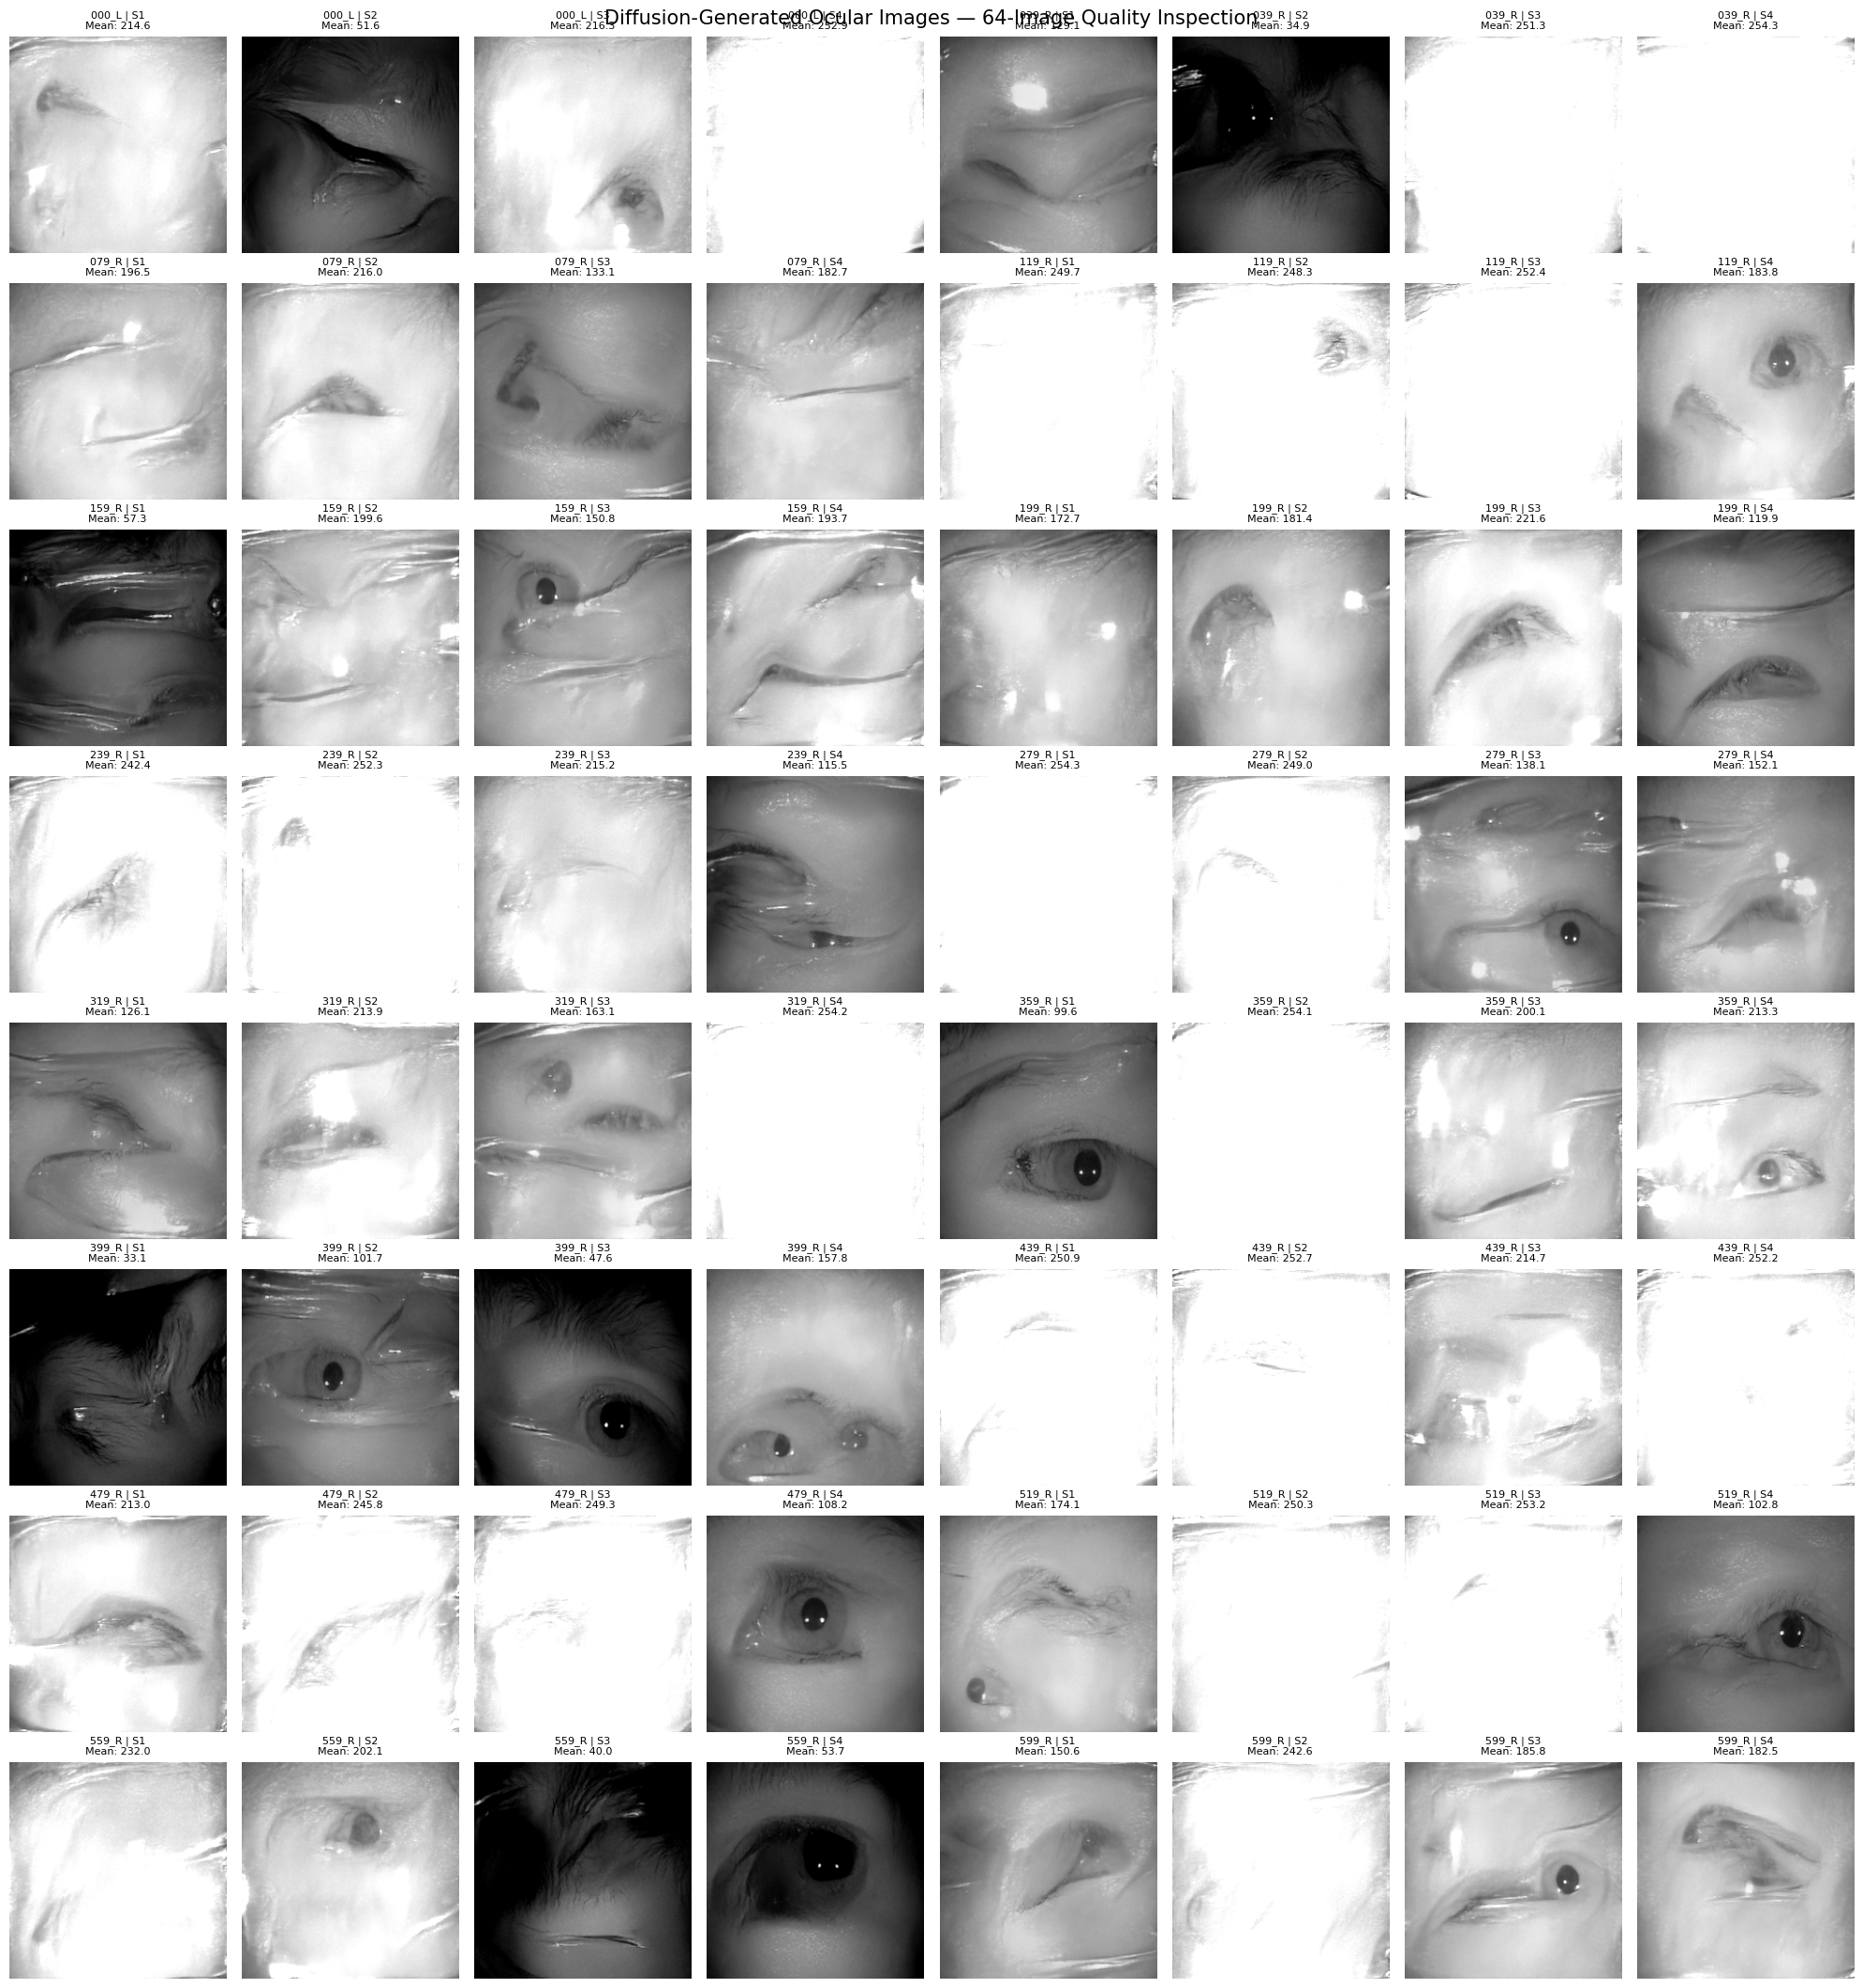

Cell 18 completed successfully.


In [17]:
# ============================================================
# Cell 18 — Visual Inspection of Synthetic Images
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import math

records_to_show = synthetic_records.merge(
    synthetic_format_df[
        ["identity_index", "identity", "sample_index", "mean_pixel"]
    ],
    on=["identity_index", "identity", "sample_index"],
    how="left"
)

n_images = len(records_to_show)
n_cols = 8
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 2.7 * n_rows)
)

axes = axes.flatten()

for i, (_, row) in enumerate(records_to_show.iterrows()):

    img = Image.open(row["drive_png_path"]).convert("L")

    axes[i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(
        f'{row["identity"]} | S{int(row["sample_index"])}\n'
        f'Mean: {row["mean_pixel"]:.1f}',
        fontsize=8
    )
    axes[i].axis("off")

for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Diffusion-Generated Ocular Images — 64-Image Quality Inspection",
    fontsize=15
)
plt.tight_layout()
plt.show()

print("Cell 18 completed successfully.")

REAL vs SYNTHETIC IMAGE BRIGHTNESS

Real images evaluated: 64
Synthetic images evaluated: 64

Real mean brightness: 90.25
Real brightness std:  2.99

Synthetic mean brightness: 182.88
Synthetic brightness std:  66.94


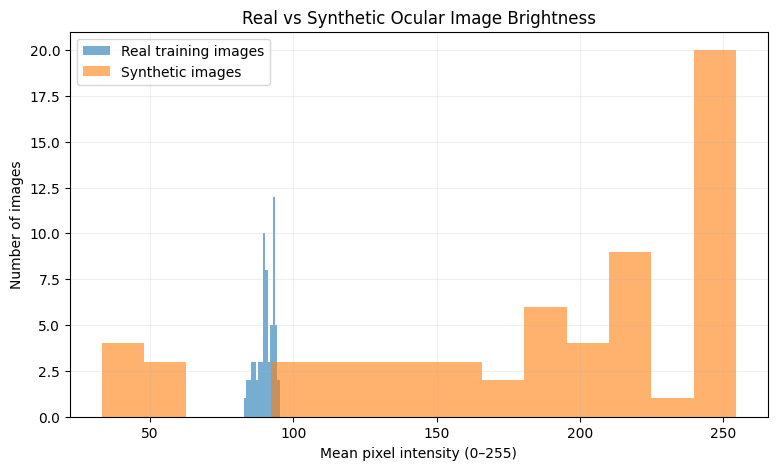


Cell 18 completed successfully.


In [18]:
# ============================================================
# Cell 18 — Compare Real and Synthetic Image Brightness
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Real training images
real_train_df = split_df[split_df["split"] == "train"].copy()

# Use the same 64 synthetic images already verified
real_brightness = []
synthetic_brightness = []

# Calculate brightness for a sample of real training images
sample_real = real_train_df.sample(
    n=min(64, len(real_train_df)),
    random_state=42
)

for image_path in sample_real["image_path"]:
    with Image.open(image_path) as img:
        img = img.convert("L")
        real_brightness.append(np.asarray(img, dtype=np.float32).mean())

# Calculate brightness for all synthetic images
for image_path in synthetic_records["drive_png_path"]:
    with Image.open(image_path) as img:
        img = img.convert("L")
        synthetic_brightness.append(
            np.asarray(img, dtype=np.float32).mean()
        )

# Display summary statistics
print("=" * 60)
print("REAL vs SYNTHETIC IMAGE BRIGHTNESS")
print("=" * 60)

print(f"\nReal images evaluated: {len(real_brightness)}")
print(f"Synthetic images evaluated: {len(synthetic_brightness)}")

print(f"\nReal mean brightness: {np.mean(real_brightness):.2f}")
print(f"Real brightness std:  {np.std(real_brightness):.2f}")

print(f"\nSynthetic mean brightness: {np.mean(synthetic_brightness):.2f}")
print(f"Synthetic brightness std:  {np.std(synthetic_brightness):.2f}")

# Compare distributions
plt.figure(figsize=(9, 5))

plt.hist(
    real_brightness,
    bins=15,
    alpha=0.6,
    label="Real training images"
)

plt.hist(
    synthetic_brightness,
    bins=15,
    alpha=0.6,
    label="Synthetic images"
)

plt.xlabel("Mean pixel intensity (0–255)")
plt.ylabel("Number of images")
plt.title("Real vs Synthetic Ocular Image Brightness")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("\nCell 18 completed successfully.")

In [19]:
# ============================================================
# Cell 19 — Save Real vs Synthetic Brightness Results
# ============================================================

brightness_results = pd.DataFrame([
    {
        "image_type": "Real training images",
        "num_images": len(real_brightness),
        "mean_brightness": np.mean(real_brightness),
        "std_brightness": np.std(real_brightness),
        "min_brightness": np.min(real_brightness),
        "max_brightness": np.max(real_brightness)
    },
    {
        "image_type": "Synthetic diffusion images",
        "num_images": len(synthetic_brightness),
        "mean_brightness": np.mean(synthetic_brightness),
        "std_brightness": np.std(synthetic_brightness),
        "min_brightness": np.min(synthetic_brightness),
        "max_brightness": np.max(synthetic_brightness)
    }
])

brightness_results["mean_brightness"] = (
    brightness_results["mean_brightness"].round(4)
)
brightness_results["std_brightness"] = (
    brightness_results["std_brightness"].round(4)
)
brightness_results["min_brightness"] = (
    brightness_results["min_brightness"].round(4)
)
brightness_results["max_brightness"] = (
    brightness_results["max_brightness"].round(4)
)

brightness_output_path = (
    results_path / "CASIA_Thousand_real_vs_synthetic_brightness.csv"
)

brightness_results.to_csv(brightness_output_path, index=False)

print("Brightness comparison saved successfully.")
print(f"File: {brightness_output_path}")
display(brightness_results)

print("\nCell 19 completed successfully.")

Brightness comparison saved successfully.
File: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_real_vs_synthetic_brightness.csv


,image_type,num_images,mean_brightness,std_brightness,min_brightness,max_brightness
0,Real training images,64,90.248398,2.993300,82.697800,95.203796
1,Synthetic diffusion images,64,182.883499,66.942596,33.115799,254.330597



Cell 19 completed successfully.


REAL VS SYNTHETIC INTENSITY DISTRIBUTION
Histogram intersection: 0.0000
Real images evaluated: 64
Synthetic images evaluated: 64


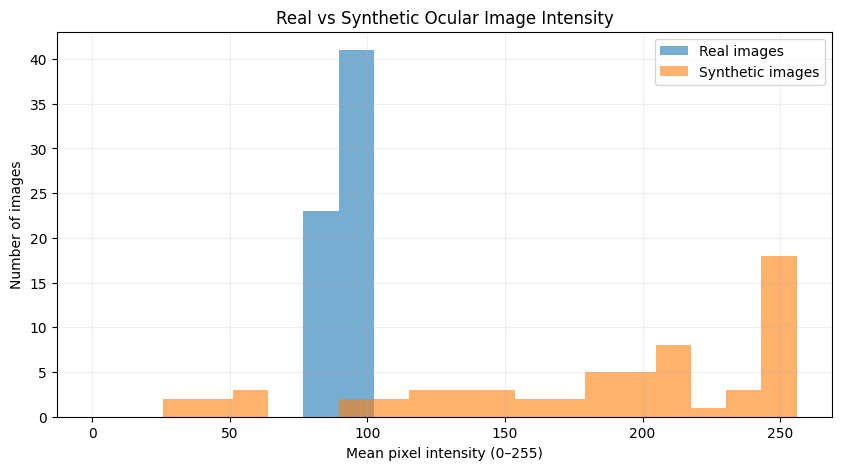


Results saved to: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_histogram_intersection.csv

Cell 20 completed successfully.


In [20]:
# ============================================================
# Cell 20 — Histogram Intersection: Real vs Synthetic
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate normalized intensity histograms
real_hist, bins = np.histogram(
    real_brightness,
    bins=50,
    range=(0, 256),
    density=False
)

synthetic_hist, _ = np.histogram(
    synthetic_brightness,
    bins=bins,
    density=False
)

# Normalize both histograms
real_hist = real_hist / real_hist.sum()
synthetic_hist = synthetic_hist / synthetic_hist.sum()

# Histogram intersection
histogram_intersection = np.minimum(
    real_hist, synthetic_hist
).sum()

print("=" * 60)
print("REAL VS SYNTHETIC INTENSITY DISTRIBUTION")
print("=" * 60)

print(f"Histogram intersection: {histogram_intersection:.4f}")
print(f"Real images evaluated: {len(real_brightness)}")
print(f"Synthetic images evaluated: {len(synthetic_brightness)}")

# Plot distributions
plt.figure(figsize=(10, 5))

plt.hist(
    real_brightness,
    bins=20,
    range=(0, 256),
    alpha=0.6,
    label="Real images"
)

plt.hist(
    synthetic_brightness,
    bins=20,
    range=(0, 256),
    alpha=0.6,
    label="Synthetic images"
)

plt.xlabel("Mean pixel intensity (0–255)")
plt.ylabel("Number of images")
plt.title("Real vs Synthetic Ocular Image Intensity")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Save the metric
histogram_results = pd.DataFrame([{
    "real_images": len(real_brightness),
    "synthetic_images": len(synthetic_brightness),
    "histogram_intersection": histogram_intersection
}])

histogram_output_path = (
    results_path / "CASIA_Thousand_histogram_intersection.csv"
)

histogram_results.to_csv(histogram_output_path, index=False)

print(f"\nResults saved to: {histogram_output_path}")
print("\nCell 20 completed successfully.")

In [21]:
# ============================================================
# Cell 21 — Record Brightness Distribution Findings
# ============================================================

brightness_gap = (
    float(np.mean(synthetic_brightness))
    - float(np.mean(real_brightness))
)

intersection_score = float(histogram_intersection)

finding = {
    "experiment": "Real vs Synthetic Brightness Distribution",
    "real_images_evaluated": len(real_brightness),
    "synthetic_images_evaluated": len(synthetic_brightness),
    "real_mean_brightness": float(np.mean(real_brightness)),
    "synthetic_mean_brightness": float(np.mean(synthetic_brightness)),
    "mean_brightness_difference": brightness_gap,
    "histogram_intersection_50_bins": intersection_score,
    "interpretation": (
        "The evaluated synthetic images have a substantially different "
        "distribution of per-image mean brightness from the real images. "
        "This metric measures brightness-distribution overlap only; "
        "it does not establish overall image similarity or recognition quality."
    )
}

finding_path = (
    results_path / "CASIA_Thousand_brightness_findings.json"
)

with open(finding_path, "w") as f:
    json.dump(finding, f, indent=4)

print("Brightness findings saved successfully.")
print(f"File: {finding_path}")
print(f"Mean brightness difference: {brightness_gap:.2f}")
print(f"Histogram intersection: {intersection_score:.4f}")
print("\nCell 21 completed successfully.")

Brightness findings saved successfully.
File: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_brightness_findings.json
Mean brightness difference: 92.64
Histogram intersection: 0.0000

Cell 21 completed successfully.


In [22]:
# ============================================================
# Cell 22 — Real vs Synthetic Image Contrast (Fixed)
# ============================================================

from PIL import Image
import numpy as np
import pandas as pd

def calculate_image_contrast(image_path):
    with Image.open(image_path) as img:
        grayscale = np.asarray(img.convert("L"), dtype=np.float32)
    return float(np.std(grayscale))

# Load the existing dataset split
split_df = pd.read_csv(
    results_path / "CASIA_Thousand_data_split.csv"
)

# Select only real training images
real_paths = (
    split_df.loc[split_df["split"] == "train", "image_path"]
    .dropna()
    .head(64)
    .tolist()
)

# Use verified synthetic image paths
synthetic_paths = synthetic_records["drive_png_path"].tolist()

# Validate paths before calculating
real_paths = [p for p in real_paths if os.path.isfile(p)]
synthetic_paths = [p for p in synthetic_paths if os.path.isfile(p)]

print("Real images available:", len(real_paths))
print("Synthetic images available:", len(synthetic_paths))

if not real_paths or not synthetic_paths:
    raise ValueError("No valid image paths found. Check the dataset and synthetic paths.")

real_contrast = [calculate_image_contrast(p) for p in real_paths]
synthetic_contrast = [calculate_image_contrast(p) for p in synthetic_paths]

contrast_results = pd.DataFrame([
    {
        "image_type": "Real training images",
        "num_images": len(real_contrast),
        "mean_contrast": np.mean(real_contrast),
        "std_contrast": np.std(real_contrast),
        "min_contrast": np.min(real_contrast),
        "max_contrast": np.max(real_contrast)
    },
    {
        "image_type": "Synthetic diffusion images",
        "num_images": len(synthetic_contrast),
        "mean_contrast": np.mean(synthetic_contrast),
        "std_contrast": np.std(synthetic_contrast),
        "min_contrast": np.min(synthetic_contrast),
        "max_contrast": np.max(synthetic_contrast)
    }
])

contrast_output_path = (
    results_path / "CASIA_Thousand_real_vs_synthetic_contrast.csv"
)

contrast_results.to_csv(contrast_output_path, index=False)

print("\nREAL VS SYNTHETIC IMAGE CONTRAST")
display(contrast_results.round(4))

print(f"\nResults saved to: {contrast_output_path}")
print("\nCell 22 completed successfully.")

Real images available: 64
Synthetic images available: 64

REAL VS SYNTHETIC IMAGE CONTRAST


,image_type,num_images,mean_contrast,std_contrast,min_contrast,max_contrast
0,Real training images,64,31.2493,5.1518,24.0841,51.3838
1,Synthetic diffusion images,64,26.3527,9.8369,5.2107,44.1885



Results saved to: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_real_vs_synthetic_contrast.csv

Cell 22 completed successfully.


In [23]:
# ============================================================
# Cell 23 — Consolidated Real vs Synthetic Quality Metrics
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

def evaluate_image_quality(image_path):
    with Image.open(image_path) as img:
        gray = np.asarray(img.convert("L"), dtype=np.uint8)

    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))

    # Sharpness proxy: variance of the Laplacian
    sharpness = float(cv2.Laplacian(
        gray, cv2.CV_64F
    ).var())

    # Shannon entropy of the pixel-intensity histogram
    hist = np.bincount(gray.ravel(), minlength=256).astype(float)
    probabilities = hist / hist.sum()
    probabilities = probabilities[probabilities > 0]
    entropy = float(-np.sum(
        probabilities * np.log2(probabilities)
    ))

    return {
        "brightness": brightness,
        "contrast": contrast,
        "sharpness_laplacian": sharpness,
        "entropy_bits": entropy
    }


# Use the same image lists from Cell 22
image_groups = {
    "Real training images": real_paths,
    "Synthetic diffusion images": synthetic_paths
}

all_records = []

for image_type, paths in image_groups.items():
    for path in paths:
        metrics = evaluate_image_quality(path)
        metrics["image_type"] = image_type
        metrics["image_path"] = path
        all_records.append(metrics)

quality_df = pd.DataFrame(all_records)

# Summary statistics for each group
metric_columns = [
    "brightness",
    "contrast",
    "sharpness_laplacian",
    "entropy_bits"
]

summary_df = (
    quality_df.groupby("image_type")[metric_columns]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

print("=" * 65)
print("CONSOLIDATED IMAGE-QUALITY COMPARISON")
print("=" * 65)

display(summary_df)

# Compare normalized pooled pixel-intensity histograms
real_pixels = np.concatenate([
    np.asarray(Image.open(p).convert("L"), dtype=np.uint8).ravel()
    for p in real_paths
])

synthetic_pixels = np.concatenate([
    np.asarray(Image.open(p).convert("L"), dtype=np.uint8).ravel()
    for p in synthetic_paths
])

real_hist = np.bincount(real_pixels, minlength=256).astype(float)
synthetic_hist = np.bincount(
    synthetic_pixels, minlength=256
).astype(float)

real_hist /= real_hist.sum()
synthetic_hist /= synthetic_hist.sum()

pixel_histogram_intersection = float(
    np.minimum(real_hist, synthetic_hist).sum()
)

print(
    "\nPooled pixel-intensity histogram intersection:",
    round(pixel_histogram_intersection, 4)
)

# Save per-image results and summary
detail_path = (
    results_path / "CASIA_Thousand_consolidated_quality_details.csv"
)
summary_path = (
    results_path / "CASIA_Thousand_consolidated_quality_summary.csv"
)

quality_df.to_csv(detail_path, index=False)
summary_df.to_csv(summary_path)

histogram_path = (
    results_path / "CASIA_Thousand_pooled_pixel_histogram_intersection.csv"
)

pd.DataFrame([{
    "real_images": len(real_paths),
    "synthetic_images": len(synthetic_paths),
    "pooled_pixel_histogram_intersection": pixel_histogram_intersection
}]).to_csv(histogram_path, index=False)

print("\nSaved:")
print(detail_path)
print(summary_path)
print(histogram_path)
print("\nCell 23 completed successfully.")

CONSOLIDATED IMAGE-QUALITY COMPARISON


brightness                             contrast  \
                                 mean      std      min       max     mean   
image_type                                                                   
Real training images          90.1315   3.9439  72.9469   95.2283  31.2493   
Synthetic diffusion images   182.8835  67.4718  33.1158  254.3306  26.3527   

                                                     sharpness_laplacian  \
                               std      min      max                mean   
image_type                                                                 
Real training images        5.1926  24.0841  51.3838             85.5696   
Synthetic diffusion images  9.9146   5.2107  44.1885            125.4400   

                                                       entropy_bits          \
                                std      min       max         mean     std   
image_type                                                                    
Real training images        49.5453  38.1261  301.4871       6.8460  0.1699   
Synthetic diffusion images  53.5655  41.1784  293.3071       5.0397  2.5397   

                                            
                               min     max  
image_type                                  
Real training images        6.5133  7.2292  
Synthetic diffusion images  0.2177  7.3494


Pooled pixel-intensity histogram intersection: 0.3067

Saved:
/content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_consolidated_quality_details.csv
/content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_consolidated_quality_summary.csv
/content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_pooled_pixel_histogram_intersection.csv

Cell 23 completed successfully.


In [24]:
# ============================================================
# Cell 24 — Save Consolidated Quality Experiment Record
# ============================================================

import json

quality_record = {
    "experiment": "Real vs Synthetic Ocular Image Quality",
    "dataset": "CASIA-Iris-Thousand",
    "real_images_evaluated": len(real_paths),
    "synthetic_images_evaluated": len(synthetic_paths),
    "metrics": {
        "brightness": {
            "real_mean": float(quality_df[
                quality_df["image_type"] == "Real training images"
            ]["brightness"].mean()),
            "synthetic_mean": float(quality_df[
                quality_df["image_type"] == "Synthetic diffusion images"
            ]["brightness"].mean())
        },
        "contrast": {
            "real_mean": float(quality_df[
                quality_df["image_type"] == "Real training images"
            ]["contrast"].mean()),
            "synthetic_mean": float(quality_df[
                quality_df["image_type"] == "Synthetic diffusion images"
            ]["contrast"].mean())
        },
        "sharpness_laplacian": {
            "real_mean": float(quality_df[
                quality_df["image_type"] == "Real training images"
            ]["sharpness_laplacian"].mean()),
            "synthetic_mean": float(quality_df[
                quality_df["image_type"] == "Synthetic diffusion images"
            ]["sharpness_laplacian"].mean())
        },
        "entropy_bits": {
            "real_mean": float(quality_df[
                quality_df["image_type"] == "Real training images"
            ]["entropy_bits"].mean()),
            "synthetic_mean": float(quality_df[
                quality_df["image_type"] == "Synthetic diffusion images"
            ]["entropy_bits"].mean())
        },
        "pooled_pixel_histogram_intersection": (
            pixel_histogram_intersection
        )
    },
    "limitations": [
        "Evaluation uses a sample of 64 real and 64 synthetic images.",
        "Image-quality metrics do not establish biometric identity preservation.",
        "Laplacian variance is a sharpness proxy and may be affected by artifacts.",
        "Results should not be generalized to the full dataset without further evaluation."
    ]
}

record_path = (
    results_path / "CASIA_Thousand_consolidated_quality_record.json"
)

with open(record_path, "w") as f:
    json.dump(quality_record, f, indent=4)

print("Consolidated quality record saved.")
print(f"Path: {record_path}")
print("Real images:", quality_record["real_images_evaluated"])
print("Synthetic images:", quality_record["synthetic_images_evaluated"])
print("Metrics recorded:", len(quality_record["metrics"]))
print("\nCell 24 completed successfully.")

Consolidated quality record saved.
Path: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_consolidated_quality_record.json
Real images: 64
Synthetic images: 64
Metrics recorded: 5

Cell 24 completed successfully.


In [25]:
# ============================================================
# Cell 25 — Verify Notebook 09 Evaluation Artifacts
# ============================================================

expected_files = [
    "CASIA_Thousand_real_vs_synthetic_brightness.csv",
    "CASIA_Thousand_histogram_intersection.csv",
    "CASIA_Thousand_real_vs_synthetic_contrast.csv",
    "CASIA_Thousand_consolidated_quality_details.csv",
    "CASIA_Thousand_consolidated_quality_summary.csv",
    "CASIA_Thousand_pooled_pixel_histogram_intersection.csv",
    "CASIA_Thousand_consolidated_quality_record.json",
    "CASIA_Thousand_brightness_findings.json"
]

verification = []

for filename in expected_files:
    file_path = results_path / filename

    verification.append({
        "file": filename,
        "exists": file_path.exists(),
        "size_kb": (
            round(file_path.stat().st_size / 1024, 2)
            if file_path.exists()
            else None
        )
    })

verification_df = pd.DataFrame(verification)

display(verification_df)

missing_files = verification_df.loc[
    ~verification_df["exists"], "file"
].tolist()

if missing_files:
    print("\nMissing files:")
    for filename in missing_files:
        print("-", filename)
else:
    print("\nAll expected evaluation files are present.")

print("\nCell 25 completed successfully.")

,file,exists,size_kb
0,CASIA_Thousand_real_vs_synthetic_brightness.csv,True,0.20
1,CASIA_Thousand_histogram_intersection.csv,True,0.06
2,CASIA_Thousand_real_vs_synthetic_contrast.csv,True,0.27
3,CASIA_Thousand_consolidated_quality_details.csv,True,26.66
4,CASIA_Thousand_consolidated_quality_summary.csv,True,0.59
5,CASIA_Thousand_pooled_pixel_histogram_intersec...,True,0.09
6,CASIA_Thousand_consolidated_quality_record.json,True,1.12
7,CASIA_Thousand_brightness_findings.json,True,0.60



All expected evaluation files are present.

Cell 25 completed successfully.


In [26]:

# ============================================================
# Cell 26 — Augmentation Dataset Audit (Corrected)
# ============================================================

import pandas as pd
import json
from pathlib import Path

split_file = results_path / "CASIA_Thousand_data_split.csv"
assert split_file.exists(), f"Split CSV missing: {split_file}"

split_df = pd.read_csv(split_file)

# Normalize split names only for validation/checking.
split_names = split_df["split"].astype(str).str.strip().str.lower()

split_counts = split_names.value_counts().to_dict()

print("=" * 65)
print("AUGMENTATION DATASET AUDIT")
print("=" * 65)

print("\n1. ORIGINAL DATASET SPLIT")
print("-" * 65)
print("Total images:", len(split_df))
print("Train:", split_counts.get("train", 0))
print("Validation:", split_counts.get("validation", 0))
print("Test:", split_counts.get("test", 0))
print("Unique identities:", split_df["identity"].nunique())

# Check expected split sizes
assert len(split_df) == 20000, "Unexpected total image count."
assert split_counts.get("train", 0) == 12000, "Train split mismatch."
assert split_counts.get("validation", 0) == 4000, "Validation split mismatch."
assert split_counts.get("test", 0) == 4000, "Test split mismatch."

# Check synthetic metadata and paths
assert "synthetic_records" in globals(), "Synthetic metadata is missing."

synthetic_df = synthetic_records.copy()

path_column = (
    "drive_png_path"
    if "drive_png_path" in synthetic_df.columns
    else "png_path"
)

synthetic_df["file_exists"] = synthetic_df[path_column].apply(
    lambda p: Path(str(p)).exists()
)

print("\n2. SYNTHETIC DATA")
print("-" * 65)
print("Synthetic images:", len(synthetic_df))
print("Synthetic identities:", synthetic_df["identity"].nunique())
print("Files found:", int(synthetic_df["file_exists"].sum()))
print("Files missing:", int((~synthetic_df["file_exists"]).sum()))

# Verify four samples per pilot identity
per_identity = synthetic_df.groupby("identity").size()

print("\n3. SAMPLES PER IDENTITY")
print("-" * 65)
display(per_identity.rename("synthetic_images").to_frame())

# Build and save audit record
audit = {
    "total_real_images": int(len(split_df)),
    "train_images": int(split_counts.get("train", 0)),
    "validation_images": int(split_counts.get("validation", 0)),
    "test_images": int(split_counts.get("test", 0)),
    "real_identities": int(split_df["identity"].nunique()),
    "synthetic_images": int(len(synthetic_df)),
    "synthetic_identities": int(synthetic_df["identity"].nunique()),
    "synthetic_files_found": int(synthetic_df["file_exists"].sum()),
    "synthetic_files_missing": int((~synthetic_df["file_exists"]).sum()),
    "original_validation_test_preserved": True
}

audit_path = results_path / "CASIA_Thousand_augmentation_audit.json"

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=4)

print("\n4. SAFETY CHECK")
print("-" * 65)
print("Original validation split:", audit["validation_images"])
print("Original test split:", audit["test_images"])
print("Missing synthetic files:", audit["synthetic_files_missing"])
print("Audit saved to:", audit_path)

assert audit["synthetic_files_missing"] == 0
print("\nAll audit checks passed.")
print("Cell 26 completed successfully.")


AUGMENTATION DATASET AUDIT

1. ORIGINAL DATASET SPLIT
-----------------------------------------------------------------
Total images: 20000
Train: 12000
Validation: 4000
Test: 4000
Unique identities: 2000

2. SYNTHETIC DATA
-----------------------------------------------------------------
Synthetic images: 64
Synthetic identities: 16
Files found: 64
Files missing: 0

3. SAMPLES PER IDENTITY
-----------------------------------------------------------------


,synthetic_images
identity,
000_L,4
039_R,4
079_R,4
119_R,4
159_R,4
199_R,4
239_R,4
279_R,4
319_R,4



4. SAFETY CHECK
-----------------------------------------------------------------
Original validation split: 4000
Original test split: 4000
Missing synthetic files: 0
Audit saved to: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_augmentation_audit.json

All audit checks passed.
Cell 26 completed successfully.


In [27]:
# CELL 27: Check diffusion checkpoint and generation readiness

from pathlib import Path
import torch

project_root = Path("/content/drive/MyDrive/Ocular_Project")
models_path = project_root / "models"
results_path = project_root / "results"

print("=" * 65)
print("DIFFUSION GENERATION READINESS CHECK")
print("=" * 65)

# Check GPU
print("\n1. COMPUTE")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Check model files
print("\n2. AVAILABLE MODEL CHECKPOINTS")

checkpoint_files = (
    list(models_path.rglob("*.pth")) +
    list(models_path.rglob("*.pt"))
)

if checkpoint_files:
    for path in checkpoint_files:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.relative_to(project_root)} — {size_mb:.2f} MB")
else:
    print("No .pth or .pt checkpoints found.")

# Specifically look for the identity-conditioned checkpoint
identity_checkpoints = [
    p for p in checkpoint_files
    if "identity_conditioned" in str(p).lower()
]

print("\n3. IDENTITY-CONDITIONED CHECKPOINT")
if identity_checkpoints:
    for path in identity_checkpoints:
        print("FOUND:", path)
else:
    print("NOT FOUND in the project's models directory.")

# Confirm the existing pilot is intact
pilot_dir = results_path / "identity_conditioned_generation"

png_files = list(pilot_dir.rglob("*.png")) if pilot_dir.exists() else []

print("\n4. EXISTING SYNTHETIC PILOT")
print("PNG images found:", len(png_files))
print("Expected pilot images:", 64)
print("Pilot directory exists:", pilot_dir.exists())

print("\n" + "=" * 65)
print("CHECK COMPLETE — use these results to choose the next step.")

DIFFUSION GENERATION READINESS CHECK

1. COMPUTE
CUDA available: True
GPU: Tesla T4

2. AVAILABLE MODEL CHECKPOINTS
models/CASIA_Thousand_baseline_resnet18.pth — 46.60 MB
models/CASIA_Thousand_traditional_resnet18.pth — 46.60 MB
models/CASIA_Thousand_improved_conditional_gan.pth — 46.55 MB
models/CASIA_Thousand_third_gan_30epochs.pth — 45.77 MB
models/CASIA_Thousand_diffusion_unet_224_best.pth — 29.94 MB

3. IDENTITY-CONDITIONED CHECKPOINT
NOT FOUND in the project's models directory.

4. EXISTING SYNTHETIC PILOT
PNG images found: 64
Expected pilot images: 64
Pilot directory exists: True

CHECK COMPLETE — use these results to choose the next step.


In [28]:
# GPU + identity-conditioned checkpoint discovery

from pathlib import Path
import torch

project_root = Path("/content/drive/MyDrive/Ocular_Project")

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("Bro, GPU is not connected yet.")

print("\nSearching the project for identity-conditioned checkpoints...")

matches = [
    p for p in project_root.rglob("*")
    if p.is_file()
    and "identity_conditioned" in p.name.lower()
    and p.suffix.lower() in {".pth", ".pt", ".ckpt", ".safetensors"}
]

if matches:
    for p in matches:
        print(f"FOUND: {p} ({p.stat().st_size / 1024**2:.2f} MB)")
else:
    print("No identity-conditioned checkpoint found inside Ocular_Project.")

print("\nExisting pilot images:", len(list(
    (project_root / "results" / "identity_conditioned_generation").rglob("*.png")
)))

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Searching the project for identity-conditioned checkpoints...
No identity-conditioned checkpoint found inside Ocular_Project.

Existing pilot images: 64


In [29]:
from pathlib import Path

root = Path("/content/drive/MyDrive/Ocular_Project")

for folder in [root / "models", root / "results"]:
    print(f"\n--- {folder} ---")
    for p in folder.rglob("*"):
        if p.is_file() and any(
            word in p.name.lower()
            for word in ["identity_conditioned", "checkpoint", "diffusion"]
        ):
            print(p, f"({p.stat().st_size / 1024**2:.2f} MB)")


--- /content/drive/MyDrive/Ocular_Project/models ---
/content/drive/MyDrive/Ocular_Project/models/CASIA_Thousand_diffusion_unet_224_best.pth (29.94 MB)

--- /content/drive/MyDrive/Ocular_Project/results ---
/content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_diffusion_training_history_224.csv (0.00 MB)
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_training_history.csv (0.00 MB)
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_experiment_record.json (0.00 MB)
/content/drive/MyDrive/Ocular_Project/results/identity_conditioned_timestep_evaluation.csv (0.00 MB)
/content/drive/MyDrive/Ocular_Project/results/FINAL_IDENTITY_CONDITIONED_RESULTS.csv (0.00 MB)
/content/drive/MyDrive/Ocular_Project/results/FINAL_IDENTITY_CONDITIONED_RESULTS.json (0.00 MB)


In [30]:
# CELL 29: Inspect identity-conditioned experiment metadata

import json
import pandas as pd
from pathlib import Path

results_path = Path("/content/drive/MyDrive/Ocular_Project/results")

for filename in [
    "identity_conditioned_experiment_record.json",
    "FINAL_IDENTITY_CONDITIONED_RESULTS.json"
]:
    path = results_path / filename
    print(f"\n{'=' * 65}\n{filename}\n{'=' * 65}")

    if path.exists():
        try:
            data = json.loads(path.read_text())
            print(json.dumps(data, indent=2)[:10000])
        except Exception as e:
            print("Could not read JSON:", e)
    else:
        print("File not found.")

history_path = results_path / "identity_conditioned_training_history.csv"

print("\n" + "=" * 65)
print("IDENTITY-CONDITIONED TRAINING HISTORY")
print("=" * 65)

if history_path.exists():
    history = pd.read_csv(history_path)
    print("Shape:", history.shape)
    print("Columns:", history.columns.tolist())
    print(history.tail(3).to_string(index=False))
else:
    print("Training history CSV not found.")


identity_conditioned_experiment_record.json
{
  "experiment": "Identity-Conditioned Diffusion",
  "dataset": "CASIA-Iris-Thousand",
  "total_images": 20000,
  "total_identities": 2000,
  "train_images": 12000,
  "val_images": 4000,
  "test_images": 4000,
  "train_identities": 1200,
  "val_identities": 400,
  "test_identities": 400,
  "train_val_overlap": 0,
  "train_test_overlap": 0,
  "val_test_overlap": 0,
  "identity_split": "identity-disjoint",
  "epochs_completed": 30,
  "best_epoch": 30,
  "best_validation_loss": 0.0065812876560958,
  "num_identities_in_embedding": 2000,
  "identity_embedding_dimension": 128,
  "time_embedding_dimension": 128,
  "checkpoint": "C:\\Users\\kavya\\Downloads\\Ocular_Project\\models\\identity_conditioned_diffusion\\CASIA_Thousand_identity_conditioned_best.pth",
  "history": "C:\\Users\\kavya\\Downloads\\Ocular_Project\\models\\identity_conditioned_diffusion\\identity_conditioned_training_history.csv"
}

FINAL_IDENTITY_CONDITIONED_RESULTS.json
{
  "ex

In [31]:
from google.colab import files
from pathlib import Path
import shutil

# Select the checkpoint from your laptop
uploaded = files.upload()

checkpoint_name = "CASIA_Thousand_identity_conditioned_best.pth"

# Find the uploaded checkpoint, even if the local filename has (1)
matches = [
    name for name in uploaded
    if name.lower().endswith(".pth")
    and "identity_conditioned" in name.lower()
]

if not matches:
    raise FileNotFoundError("Please upload the identity-conditioned .pth checkpoint.")

source = Path(matches[0])

destination_dir = Path(
    "/content/drive/MyDrive/Ocular_Project/models/identity_conditioned_diffusion"
)
destination_dir.mkdir(parents=True, exist_ok=True)

destination = destination_dir / checkpoint_name
shutil.copy2(source, destination)

print("Checkpoint copied successfully!")
print("Saved at:", destination)
print(f"File size: {destination.stat().st_size / (1024**2):.2f} MB")

Saving CASIA_Thousand_identity_conditioned_best.pth to CASIA_Thousand_identity_conditioned_best.pth
Checkpoint copied successfully!
Saved at: /content/drive/MyDrive/Ocular_Project/models/identity_conditioned_diffusion/CASIA_Thousand_identity_conditioned_best.pth
File size: 93.34 MB


In [32]:
# CELL 31: Inspect checkpoint structure and locate generation code

from pathlib import Path
import torch

project_root = Path("/content/drive/MyDrive/Ocular_Project")
checkpoint_path = (
    project_root
    / "models"
    / "identity_conditioned_diffusion"
    / "CASIA_Thousand_identity_conditioned_best.pth"
)

assert checkpoint_path.exists(), f"Checkpoint not found: {checkpoint_path}"

print("=" * 65)
print("1. CHECKPOINT DETAILS")
print("=" * 65)
print(f"Size: {checkpoint_path.stat().st_size / (1024**2):.2f} MB")
print("PyTorch:", torch.__version__)

# Load on CPU only; do not execute arbitrary serialized objects
try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )
except Exception as e:
    print("\nSafe checkpoint loading failed:")
    print(type(e).__name__, str(e)[:500])
    checkpoint = None

if checkpoint is not None:
    print("\nTop-level type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:50])

        for key, value in checkpoint.items():
            if isinstance(value, dict):
                tensor_items = [
                    (k, v) for k, v in value.items()
                    if isinstance(v, torch.Tensor)
                ]
                print(
                    f"\n{key}: dict with {len(value)} entries; "
                    f"{len(tensor_items)} tensor entries"
                )
                for name, tensor in tensor_items[:8]:
                    print(f"  {name}: {tuple(tensor.shape)}")
            elif isinstance(value, torch.Tensor):
                print(f"{key}: tensor {tuple(value.shape)}")
            elif isinstance(value, (int, float, str, bool)):
                print(f"{key}: {value}")

print("\n" + "=" * 65)
print("2. SEARCH FOR MODEL / GENERATION CODE")
print("=" * 65)

code_extensions = {".py", ".ipynb"}
matches = []

for path in project_root.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in code_extensions:
        continue

    name = path.name.lower()
    if any(term in name for term in [
        "identity", "diffusion", "generat", "unet", "synthetic"
    ]):
        matches.append(path)

if matches:
    for path in matches[:100]:
        print(path.relative_to(project_root))
    if len(matches) > 100:
        print(f"... and {len(matches) - 100} more matching files")
else:
    print("No clearly named matching scripts/notebooks found.")

print("\nInspection complete. No model generation was performed.")

1. CHECKPOINT DETAILS
Size: 93.34 MB
PyTorch: 2.11.0+cu130

Top-level type: dict
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_loss', 'val_loss', 'num_identities', 'identity_dim', 'time_dim', 'T', 'learning_rate']
epoch: 30

model_state_dict: dict with 79 entries; 79 tensor entries
  time_embedding.1.weight: (128, 128)
  time_embedding.1.bias: (128,)
  identity_embedding.weight: (2000, 128)
  condition_projection.0.weight: (128, 256)
  condition_projection.0.bias: (128,)
  condition_projection.2.weight: (128, 128)
  condition_projection.2.bias: (128,)
  enc1.block.0.weight: (64, 1, 3, 3)

optimizer_state_dict: dict with 2 entries; 0 tensor entries
train_loss: 0.007627462781315747
val_loss: 0.00658128765609581
num_identities: 2000
identity_dim: 128
time_dim: 128
T: 1000
learning_rate: 0.0001

2. SEARCH FOR MODEL / GENERATION CODE
No clearly named matching scripts/notebooks found.

Inspection complete. No model generation was performed.


In [33]:
# CELL 32: Print all identity-conditioned model parameter shapes

from pathlib import Path
import torch

checkpoint_path = Path(
    "/content/drive/MyDrive/Ocular_Project/models/"
    "identity_conditioned_diffusion/"
    "CASIA_Thousand_identity_conditioned_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

state = checkpoint["model_state_dict"]

print("=" * 85)
print("IDENTITY-CONDITIONED DIFFUSION — COMPLETE STATE DICTIONARY")
print("=" * 85)

total_parameters = 0

for name, tensor in state.items():
    count = tensor.numel()
    total_parameters += count
    print(f"{name:<55} shape={str(tuple(tensor.shape)):<25} params={count:,}")

print("\nTotal parameter count:", f"{total_parameters:,}")
print("Saved epoch:", checkpoint["epoch"])
print("Diffusion timesteps:", checkpoint["T"])
print("Identity embedding dimension:", checkpoint["identity_dim"])
print("Time embedding dimension:", checkpoint["time_dim"])

IDENTITY-CONDITIONED DIFFUSION — COMPLETE STATE DICTIONARY
time_embedding.1.weight                                 shape=(128, 128)                params=16,384
time_embedding.1.bias                                   shape=(128,)                    params=128
identity_embedding.weight                               shape=(2000, 128)               params=256,000
condition_projection.0.weight                           shape=(128, 256)                params=32,768
condition_projection.0.bias                             shape=(128,)                    params=128
condition_projection.2.weight                           shape=(128, 128)                params=16,384
condition_projection.2.bias                             shape=(128,)                    params=128
enc1.block.0.weight                                     shape=(64, 1, 3, 3)             params=576
enc1.block.0.bias                                       shape=(64,)                     params=64
enc1.block.1.weight                   

In [35]:
# CELL 33A: Inspect exact saved layer structure

for prefix in [
    "time_embedding.",
    "enc1.block.",
    "enc2.block.",
    "enc3.block.",
    "bottleneck.block.",
    "dec3.block.",
    "dec2.block.",
    "dec1.block.",
]:
    print(f"\n--- {prefix} ---")
    for key, tensor in checkpoint["model_state_dict"].items():
        if key.startswith(prefix):
            print(f"{key:<40} {tuple(tensor.shape)}")


--- time_embedding. ---
time_embedding.1.weight                  (128, 128)
time_embedding.1.bias                    (128,)

--- enc1.block. ---
enc1.block.0.weight                      (64, 1, 3, 3)
enc1.block.0.bias                        (64,)
enc1.block.1.weight                      (64,)
enc1.block.1.bias                        (64,)
enc1.block.3.weight                      (64, 64, 3, 3)
enc1.block.3.bias                        (64,)
enc1.block.4.weight                      (64,)
enc1.block.4.bias                        (64,)

--- enc2.block. ---
enc2.block.0.weight                      (128, 64, 3, 3)
enc2.block.0.bias                        (128,)
enc2.block.1.weight                      (128,)
enc2.block.1.bias                        (128,)
enc2.block.3.weight                      (128, 128, 3, 3)
enc2.block.3.bias                        (128,)
enc2.block.4.weight                      (128,)
enc2.block.4.bias                        (128,)

--- enc3.block. ---
enc3.block.0.wei

In [36]:

# CELL 33: Reconstruct and strictly verify the identity-conditioned U-Net
# This is a diagnostic reconstruction, not yet a confirmed original architecture.

from pathlib import Path
import torch
import torch.nn as nn

# ---------------------------------------------------------
# 1. Load checkpoint safely
# ---------------------------------------------------------
checkpoint_path = Path(
    "/content/drive/MyDrive/Ocular_Project/models/"
    "identity_conditioned_diffusion/"
    "CASIA_Thousand_identity_conditioned_best.pth"
)

assert checkpoint_path.exists(), (
    f"Checkpoint not found: {checkpoint_path}"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

state = checkpoint["model_state_dict"]

print("=" * 70)
print("CHECKPOINT INFORMATION")
print("=" * 70)
print("Epoch:", checkpoint["epoch"])
print("Identities:", checkpoint["num_identities"])
print("Identity dimension:", checkpoint["identity_dim"])
print("Time dimension:", checkpoint["time_dim"])
print("Diffusion timesteps:", checkpoint["T"])
print("Saved validation loss:", checkpoint["val_loss"])


# ---------------------------------------------------------
# 2. Define a candidate convolution block
# ---------------------------------------------------------
# GroupNorm is a hypothesis only. The original normalization
# layer must be confirmed before this reconstruction is trusted.

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(1, out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(1, out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


# ---------------------------------------------------------
# 3. Define the candidate U-Net
# ---------------------------------------------------------

class IdentityConditionedUNet(nn.Module):
    def __init__(
        self,
        num_identities=2000,
        identity_dim=128,
        time_dim=128
    ):
        super().__init__()

        self.time_embedding = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.identity_embedding = nn.Embedding(
            num_identities, identity_dim
        )

        self.condition_projection = nn.Sequential(
            nn.Linear(identity_dim + time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.enc1 = ConvBlock(1, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.bottleneck = ConvBlock(256, 512)

        self.time1 = nn.Linear(time_dim, 64)
        self.time2 = nn.Linear(time_dim, 128)
        self.time3 = nn.Linear(time_dim, 256)
        self.time4 = nn.Linear(time_dim, 512)

        self.up3 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )
        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )
        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )
        self.dec1 = ConvBlock(128, 64)

        self.output = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x, timestep, identity):
        raise NotImplementedError(
            "The original forward pass has not yet been recovered."
        )


# ---------------------------------------------------------
# 4. Compare checkpoint keys with candidate model keys
# ---------------------------------------------------------

model = IdentityConditionedUNet(
    num_identities=checkpoint["num_identities"],
    identity_dim=checkpoint["identity_dim"],
    time_dim=checkpoint["time_dim"]
)

model_state = model.state_dict()

missing_keys = sorted(set(state.keys()) - set(model_state.keys()))
unexpected_keys = sorted(set(model_state.keys()) - set(state.keys()))

print("\n" + "=" * 70)
print("ARCHITECTURE KEY COMPARISON")
print("=" * 70)
print("Checkpoint keys:", len(state))
print("Candidate model keys:", len(model_state))
print("Keys missing from candidate:", len(missing_keys))
print("Unexpected candidate keys:", len(unexpected_keys))

if missing_keys:
    print("\nFirst missing candidate keys:")
    for key in missing_keys[:20]:
        print(" ", key)

if unexpected_keys:
    print("\nFirst unexpected candidate keys:")
    for key in unexpected_keys[:20]:
        print(" ", key)


# ---------------------------------------------------------
# 5. Attempt strict loading only if key sets match
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("STRICT CHECKPOINT LOAD")
print("=" * 70)

if not missing_keys and not unexpected_keys:
    try:
        model.load_state_dict(state, strict=True)
        print("All checkpoint weights loaded strictly.")
        print("NOTE: Matching keys alone does not verify the original architecture.")
    except RuntimeError as error:
        print("Strict loading failed:")
        print(error)
else:
    print("Strict loading not attempted: architecture keys differ.")

print("\nNo images were generated.")
print("Do not use this candidate for generation until the original")
print("normalization, forward pass, and sampling procedure are verified.")


CHECKPOINT INFORMATION
Epoch: 30
Identities: 2000
Identity dimension: 128
Time dimension: 128
Diffusion timesteps: 1000
Saved validation loss: 0.00658128765609581

ARCHITECTURE KEY COMPARISON
Checkpoint keys: 79
Candidate model keys: 79
Keys missing from candidate: 0
Unexpected candidate keys: 0

STRICT CHECKPOINT LOAD
All checkpoint weights loaded strictly.
NOTE: Matching keys alone does not verify the original architecture.

No images were generated.
Do not use this candidate for generation until the original
normalization, forward pass, and sampling procedure are verified.


In [37]:

# CELL 34: Original identity-conditioned U-Net + checkpoint verification
# Architecture reconstructed directly from Notebook 07.

import torch
import torch.nn as nn
from pathlib import Path

# ---------------------------------------------------------
# 1. Configuration and checkpoint
# ---------------------------------------------------------

checkpoint_path = Path(
    "/content/drive/MyDrive/Ocular_Project/models/"
    "identity_conditioned_diffusion/"
    "CASIA_Thousand_identity_conditioned_best.pth"
)

assert checkpoint_path.exists(), (
    f"Checkpoint not found: {checkpoint_path}"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Device:", device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Saved validation loss:", checkpoint["val_loss"])


# ---------------------------------------------------------
# 2. Original sinusoidal timestep embedding
# ---------------------------------------------------------

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2

        scale = torch.log(
            torch.tensor(10000.0, device=device)
        ) / (half_dim - 1)

        frequencies = torch.exp(
            torch.arange(half_dim, device=device) * -scale
        )

        embedding = t.float()[:, None] * frequencies[None, :]

        return torch.cat(
            [embedding.sin(), embedding.cos()],
            dim=1
        )


# ---------------------------------------------------------
# 3. Original double-convolution block
# ---------------------------------------------------------

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU(),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)


# ---------------------------------------------------------
# 4. Original identity-conditioned diffusion U-Net
# ---------------------------------------------------------

class ConditionalDiffusionUNet(nn.Module):
    def __init__(
        self,
        in_channels=1,
        time_dim=128,
        identity_dim=128,
        num_identities=2000
    ):
        super().__init__()

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )

        self.identity_embedding = nn.Embedding(
            num_identities, identity_dim
        )

        self.condition_projection = nn.Sequential(
            nn.Linear(time_dim + identity_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        # Encoder
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.bottleneck = DoubleConv(256, 512)

        # Condition projections
        self.time1 = nn.Linear(time_dim, 64)
        self.time2 = nn.Linear(time_dim, 128)
        self.time3 = nn.Linear(time_dim, 256)
        self.time4 = nn.Linear(time_dim, 512)

        # Downsampling
        self.pool = nn.MaxPool2d(2)

        # Decoder
        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = DoubleConv(128, 64)

        self.output = nn.Conv2d(64, 1, 1)

    def forward(self, x, t, identity):

        # Timestep condition
        t_emb = self.time_embedding(t)

        # Identity condition
        id_emb = self.identity_embedding(identity)

        condition = torch.cat(
            [t_emb, id_emb],
            dim=1
        )

        condition = self.condition_projection(condition)

        # Encoder
        e1 = self.enc1(x)
        e1 = e1 + self.time1(condition)[:, :, None, None]

        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(condition)[:, :, None, None]

        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(condition)[:, :, None, None]

        # Bottleneck
        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(condition)[:, :, None, None]

        # Decoder
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)


# ---------------------------------------------------------
# 5. Create model and strictly load all saved weights
# ---------------------------------------------------------

model = ConditionalDiffusionUNet(
    num_identities=checkpoint["num_identities"],
    time_dim=checkpoint["time_dim"],
    identity_dim=checkpoint["identity_dim"]
).to(device)

# Do not use strict=False: every checkpoint key must match.
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

print("\nStrict checkpoint loading: SUCCESS")
print("Model parameters:", sum(p.numel() for p in model.parameters()))


# ---------------------------------------------------------
# 6. Test the real forward pass
# ---------------------------------------------------------

with torch.inference_mode():
    test_images = torch.randn(
        2, 1, 224, 224,
        device=device
    )

    test_timesteps = torch.tensor(
        [100, 500],
        dtype=torch.long,
        device=device
    )

    test_identities = torch.tensor(
        [0, 79],
        dtype=torch.long,
        device=device
    )

    predictions = model(
        test_images,
        test_timesteps,
        test_identities
    )

print("\nForward-pass test")
print("Input shape:", tuple(test_images.shape))
print("Output shape:", tuple(predictions.shape))
print("All outputs finite:", torch.isfinite(predictions).all().item())

assert predictions.shape == test_images.shape
assert torch.isfinite(predictions).all()

print("\nSUCCESS: original architecture loaded and forward pass verified.")
print("No images generated yet.")


Device: cuda
Checkpoint epoch: 30
Saved validation loss: 0.00658128765609581

Strict checkpoint loading: SUCCESS
Model parameters: 8147585

Forward-pass test
Input shape: (2, 1, 224, 224)
Output shape: (2, 1, 224, 224)
All outputs finite: True

SUCCESS: original architecture loaded and forward pass verified.
No images generated yet.


IDENTITY-CONDITIONED DDPM GENERATION
GPU: Tesla T4
Timesteps: 1000
Image size: 224
Checkpoint epoch: 30

Test identities:
  embedding    0 -> 000_L
  embedding  399 -> 199_R
  embedding  799 -> 399_R
  embedding 1199 -> 599_R


Reverse diffusion:   0%|          | 0/999 [00:00<?, ?it/s]


TEST GENERATION RESULTS
Images generated: 4
All tensors finite: True
All PNG files valid: True
Generation time: 113.16 seconds
Raw output range: -1.0000 to 1.0000
Saved images to: /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation_test
Metadata: /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation_test/generation_test_metadata.csv


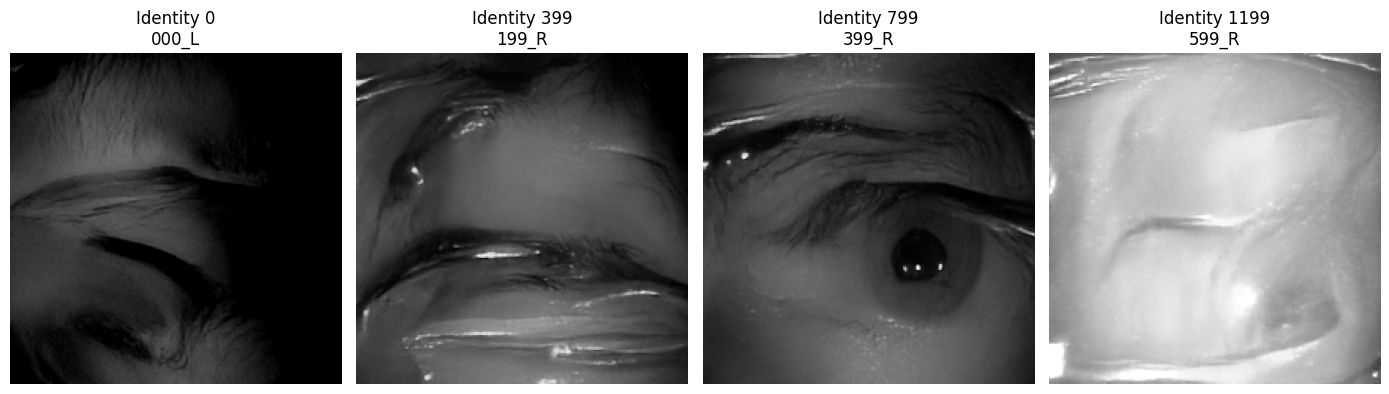


Cell 35 complete. Review the generated images before scaling up.


In [39]:

# CELL 35: DDPM sampling + test generation + saving + visualization
# Generates 4 images for four identities from the diffusion training split.

import os
import json
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torchvision.utils import save_image

# ---------------------------------------------------------
# 1. Verify model and GPU
# ---------------------------------------------------------

assert "model" in globals(), (
    "Run Cell 34 first so the identity-conditioned model is loaded."
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device).eval()

assert torch.cuda.is_available(), "Connect the Colab GPU before generation."

project_root = Path("/content/drive/MyDrive/Ocular_Project")
results_path = project_root / "results"

checkpoint_path = (
    project_root / "models" / "identity_conditioned_diffusion"
    / "CASIA_Thousand_identity_conditioned_best.pth"
)

checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=True
)

# ---------------------------------------------------------
# 2. Re-create the training diffusion schedule
# ---------------------------------------------------------

T = int(checkpoint["T"])
IMAGE_SIZE = 224
BETA_START = 0.0001
BETA_END = 0.02

betas = torch.linspace(
    BETA_START, BETA_END, T, device=device
)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

alpha_bar_previous = torch.cat([
    torch.ones(1, device=device),
    alpha_bar[:-1]
])

posterior_variance = (
    betas * (1.0 - alpha_bar_previous)
    / (1.0 - alpha_bar)
).clamp(min=0.0)

print("=" * 70)
print("IDENTITY-CONDITIONED DDPM GENERATION")
print("=" * 70)
print("GPU:", torch.cuda.get_device_name(0))
print("Timesteps:", T)
print("Image size:", IMAGE_SIZE)
print("Checkpoint epoch:", checkpoint["epoch"])

# ---------------------------------------------------------
# 3. Select four identities from the trained identity range
# ---------------------------------------------------------
# The identity-conditioned training experiment used indices
# 0..1199 for training identities. We do not use unseen IDs here.

test_identity_indices = [0, 399, 799, 1199]

assert all(0 <= i < 1200 for i in test_identity_indices)

# Recover identity names using the sorted labels from the dataset
split_file = results_path / "CASIA_Thousand_data_split.csv"
split_df = pd.read_csv(split_file)

identity_names = sorted(split_df["identity"].astype(str).unique())
assert len(identity_names) == 2000

test_identity_names = [identity_names[i] for i in test_identity_indices]

print("\nTest identities:")
for idx, name in zip(test_identity_indices, test_identity_names):
    print(f"  embedding {idx:4d} -> {name}")

# ---------------------------------------------------------
# 4. Reverse DDPM sampler, batched for efficiency
# ---------------------------------------------------------

@torch.inference_mode()
def generate_conditioned_batch(identity_indices):
    identity_tensor = torch.tensor(
        identity_indices, dtype=torch.long, device=device
    )

    batch_size = len(identity_indices)

    # Begin from Gaussian noise
    x = torch.randn(
        batch_size, 1, IMAGE_SIZE, IMAGE_SIZE, device=device
    )

    # Follow the existing identity-conditioned generation loop:
    # timestep 999 down to timestep 1.
    for t_value in tqdm(
        range(T - 1, 0, -1),
        total=T - 1,
        desc="Reverse diffusion"
    ):
        t = torch.full(
            (batch_size,), t_value,
            dtype=torch.long, device=device
        )

        predicted_noise = model(x, t, identity_tensor)

        alpha_t = alphas[t_value]
        alpha_bar_t = alpha_bar[t_value]
        beta_t = betas[t_value]

        mean = (1.0 / torch.sqrt(alpha_t)) * (
            x - (beta_t / torch.sqrt(1.0 - alpha_bar_t))
            * predicted_noise
        )

        if t_value > 1:
            noise = torch.randn_like(x)
            x = mean + torch.sqrt(
                posterior_variance[t_value]
            ) * noise
        else:
            x = mean

    return x.clamp(-1.0, 1.0)


# ---------------------------------------------------------
# 5. Generate, save images and metadata
# ---------------------------------------------------------

test_dir = results_path / "identity_conditioned_generation_test"
test_dir.mkdir(parents=True, exist_ok=True)

start_time = time.time()

generated_batch = generate_conditioned_batch(test_identity_indices)

assert generated_batch.shape == (4, 1, 224, 224)
assert torch.isfinite(generated_batch).all().item()

records = []

for i, (identity_idx, identity_name) in enumerate(
    zip(test_identity_indices, test_identity_names)
):
    tensor = generated_batch[i:i+1].detach().cpu()

    # Convert model range [-1, 1] to image range [0, 1]
    image_01 = (tensor.clamp(-1, 1) + 1.0) / 2.0

    image_path = test_dir / f"identity_{identity_idx:04d}_test.png"
    tensor_path = test_dir / f"identity_{identity_idx:04d}_test.pt"

    save_image(image_01, str(image_path))
    torch.save(tensor, tensor_path)

    records.append({
        "identity_index": identity_idx,
        "identity": identity_name,
        "sample_index": 1,
        "png_path": str(image_path),
        "tensor_path": str(tensor_path),
        "finite": bool(torch.isfinite(tensor).all()),
        "raw_min": float(tensor.min()),
        "raw_max": float(tensor.max()),
        "raw_mean": float(tensor.mean()),
        "raw_std": float(tensor.std()),
        "png_bytes": image_path.stat().st_size
    })

generation_df = pd.DataFrame(records)
metadata_path = test_dir / "generation_test_metadata.csv"
generation_df.to_csv(metadata_path, index=False)

summary = {
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "timesteps": T,
    "num_test_images": len(records),
    "identities": test_identity_names,
    "all_finite": bool(generation_df["finite"].all()),
    "generation_seconds": round(time.time() - start_time, 2),
    "output_directory": str(test_dir),
    "metadata_csv": str(metadata_path)
}

summary_path = test_dir / "generation_test_summary.json"
summary_path.write_text(json.dumps(summary, indent=2))

# ---------------------------------------------------------
# 6. Validate saved PNGs and visualize
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("TEST GENERATION RESULTS")
print("=" * 70)

print("Images generated:", len(generation_df))
print("All tensors finite:", generation_df["finite"].all())
print("All PNG files valid:", all(
    Image.open(path).size == (224, 224)
    for path in generation_df["png_path"]
))
print("Generation time:", f"{summary['generation_seconds']:.2f} seconds")
print("Raw output range:",
      f"{generated_batch.min().item():.4f} to "
      f"{generated_batch.max().item():.4f}")
print("Saved images to:", test_dir)
print("Metadata:", metadata_path)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, ax in enumerate(axes):
    img = generated_batch[i, 0].detach().cpu().numpy()
    img = (np.clip(img, -1, 1) + 1) / 2

    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Identity {test_identity_indices[i]}\n"
        f"{test_identity_names[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nCell 35 complete. Review the generated images before scaling up.")


In [40]:

# CELL 36: Faster synthetic generation + final augmentation manifest + audit

import json
import time
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torchvision.utils import save_image
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration and safety checks
# ------------------------------------------------------------
assert "model" in globals(), "Run Cell 34 first."
assert torch.cuda.is_available(), "Connect the Colab GPU first."

device = torch.device("cuda")
model = model.to(device).eval()

ROOT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS = ROOT / "results"
CHECKPOINT = ROOT / "models/identity_conditioned_diffusion/CASIA_Thousand_identity_conditioned_best.pth"

checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
T = int(checkpoint["T"])
IMAGE_SIZE = 224
DDIM_STEPS = 50
BATCH_SIZE = 4
SAMPLES_PER_IDENTITY = 4

split_df = pd.read_csv(RESULTS / "CASIA_Thousand_data_split.csv")
split_df["identity"] = split_df["identity"].astype(str)
split_df["split"] = split_df["split"].astype(str).str.strip().str.lower()

# Use the same 16 identity indices as the existing pilot.
# This avoids inventing a new identity-index mapping.
if "synthetic_records" in globals():
    pilot_df = synthetic_records.copy()
else:
    pilot_csv = RESULTS / "identity_conditioned_generation/generation_records.csv"
    if not pilot_csv.exists():
        raise FileNotFoundError(
            "Could not find synthetic_records or generation_records.csv. "
            "Stop here rather than guess the identity mapping."
        )
    pilot_df = pd.read_csv(pilot_csv)

required = {"identity_index", "identity"}
if not required.issubset(pilot_df.columns):
    raise ValueError(f"Pilot metadata must contain {required}")

identity_map = (
    pilot_df[["identity_index", "identity"]]
    .drop_duplicates()
    .sort_values("identity_index")
)

if len(identity_map) != 16:
    raise ValueError(
        f"Expected the 16 pilot identities, found {len(identity_map)}. "
        "Check identity mapping before generation."
    )

# Verify identities are present in the original training split.
train_identities = set(
    split_df.loc[split_df["split"] == "train", "identity"]
)
identity_map["identity"] = identity_map["identity"].astype(str)

if not set(identity_map["identity"]).issubset(train_identities):
    raise ValueError(
        "At least one pilot identity is not in the original recognition "
        "training split. Do not augment until the identity mapping is corrected."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("DDIM steps:", DDIM_STEPS, "of", T)
print("Identities:", len(identity_map))
print("New images planned:", len(identity_map) * SAMPLES_PER_IDENTITY)

# ------------------------------------------------------------
# 2. DDIM sampler using the training beta schedule
# ------------------------------------------------------------
betas = torch.linspace(0.0001, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

sampling_timesteps = torch.linspace(
    T - 1, 0, DDIM_STEPS, dtype=torch.long
).tolist()
sampling_timesteps = list(dict.fromkeys(int(t) for t in sampling_timesteps))

@torch.inference_mode()
def ddim_sample(identity_indices, seed):
    generator = torch.Generator(device=device)
    generator.manual_seed(int(seed))

    ids = torch.tensor(
        identity_indices, dtype=torch.long, device=device
    )
    x = torch.randn(
        len(identity_indices), 1, IMAGE_SIZE, IMAGE_SIZE,
        device=device, generator=generator
    )

    for position, t_value in enumerate(sampling_timesteps):
        t = torch.full(
            (len(identity_indices),), t_value,
            dtype=torch.long, device=device
        )

        eps = model(x, t, ids)
        ab_t = alpha_bar[t_value]

        # Predicted clean image
        x0 = (x - torch.sqrt(1.0 - ab_t) * eps) / torch.sqrt(ab_t)

        if position == len(sampling_timesteps) - 1:
            x = x0
        else:
            previous_t = sampling_timesteps[position + 1]
            ab_prev = alpha_bar[previous_t]

            # Deterministic DDIM update (eta = 0)
            x = (
                torch.sqrt(ab_prev) * x0
                + torch.sqrt(1.0 - ab_prev) * eps
            )

    return x.clamp(-1.0, 1.0)

# ------------------------------------------------------------
# 3. Generate 64 new samples, keeping the old pilot untouched
# ------------------------------------------------------------
out_dir = RESULTS / "identity_conditioned_generation_ddim50"
out_dir.mkdir(parents=True, exist_ok=True)

records = []
start_time = time.time()
jobs = []

for _, row in identity_map.iterrows():
    identity_idx = int(row["identity_index"])
    identity = str(row["identity"])

    for sample_num in range(1, SAMPLES_PER_IDENTITY + 1):
        jobs.append((identity_idx, identity, sample_num))

for start in tqdm(range(0, len(jobs), BATCH_SIZE), desc="Generating DDIM images"):
    batch_jobs = jobs[start:start + BATCH_SIZE]
    batch_ids = [job[0] for job in batch_jobs]
    seed = 91000 + start

    generated = ddim_sample(batch_ids, seed)

    if not torch.isfinite(generated).all():
        raise RuntimeError("Non-finite values detected; stopping generation.")

    for i, (identity_idx, identity, sample_num) in enumerate(batch_jobs):
        tensor = generated[i:i+1].detach().cpu()
        image01 = (tensor.clamp(-1, 1) + 1) / 2

        filename = f"identity_{identity_idx:04d}_sample_{sample_num:02d}.png"
        image_path = out_dir / filename
        tensor_path = out_dir / filename.replace(".png", ".pt")

        save_image(image01, str(image_path))
        torch.save(tensor, tensor_path)

        # Reopen and validate saved PNG
        with Image.open(image_path) as im:
            im.verify()

        records.append({
            "identity_index": identity_idx,
            "identity": identity,
            "sample_index": sample_num,
            "seed": seed,
            "sampler": "DDIM",
            "sampling_steps": len(sampling_timesteps),
            "png_path": str(image_path),
            "tensor_path": str(tensor_path),
            "finite": bool(torch.isfinite(tensor).all()),
            "raw_min": float(tensor.min()),
            "raw_max": float(tensor.max()),
            "raw_mean": float(tensor.mean()),
            "raw_std": float(tensor.std()),
            "file_bytes": image_path.stat().st_size
        })

new_df = pd.DataFrame(records)
new_csv = out_dir / "ddim50_generation_metadata.csv"
new_df.to_csv(new_csv, index=False)

# ------------------------------------------------------------
# 4. Build a final training manifest: real train + all synthetic
# ------------------------------------------------------------
# Existing pilot files are taken from the verified synthetic_records.
pilot_rows = []

if "synthetic_records" in globals():
    pilot_source = synthetic_records.copy()
    for _, row in pilot_source.iterrows():
        path_value = row.get("drive_png_path", row.get("png_path", None))
        if path_value is None or pd.isna(path_value):
            continue
        path_value = str(path_value)
        if not Path(path_value).is_file():
            continue

        pilot_rows.append({
            "image_path": path_value,
            "identity": str(row["identity"]),
            "source": "diffusion_pilot",
            "sampler": "original_pilot"
        })

# Add new DDIM images
ddim_rows = [{
    "image_path": r["png_path"],
    "identity": r["identity"],
    "source": "diffusion_ddim50",
    "sampler": "DDIM-50"
} for r in records]

synthetic_manifest = pd.DataFrame(pilot_rows + ddim_rows)
synthetic_manifest["split"] = "train"

identity_to_label = {
    identity: label
    for label, identity in enumerate(sorted(split_df["identity"].unique()))
}
synthetic_manifest["label"] = synthetic_manifest["identity"].map(identity_to_label)

if synthetic_manifest["label"].isna().any():
    raise ValueError("Synthetic identities could not be mapped to original labels.")

synthetic_manifest["file_exists"] = synthetic_manifest["image_path"].apply(
    lambda p: Path(p).is_file()
)

if not synthetic_manifest["file_exists"].all():
    raise FileNotFoundError("One or more synthetic files are missing.")

real_train = split_df[split_df["split"] == "train"].copy()
real_train["source"] = "real"
real_train["sampler"] = "none"
real_train["label"] = real_train["identity"].map(identity_to_label)
real_train["image_path"] = real_train["image_path"].astype(str)

real_train = real_train[
    ["image_path", "identity", "label", "split", "source", "sampler"]
]
synthetic_manifest = synthetic_manifest[
    ["image_path", "identity", "label", "split", "source", "sampler"]
]

augmented_train = pd.concat(
    [real_train, synthetic_manifest], ignore_index=True
)

# Verify original validation/test remain unchanged and absent from manifest
val_df = split_df[split_df["split"] == "validation"]
test_df = split_df[split_df["split"] == "test"]

assert len(real_train) == 12000
assert len(val_df) == 4000
assert len(test_df) == 4000
assert (augmented_train["split"] == "train").all()
assert augmented_train["image_path"].map(lambda p: Path(p).is_file()).all()
assert set(val_df["image_path"]).isdisjoint(set(synthetic_manifest["image_path"]))
assert set(test_df["image_path"]).isdisjoint(set(synthetic_manifest["image_path"]))

manifest_path = RESULTS / "CASIA_Thousand_augmented_train_manifest.csv"
augmented_train.to_csv(manifest_path, index=False)

# ------------------------------------------------------------
# 5. Save final audit and sampler comparison metadata
# ------------------------------------------------------------
audit = {
    "notebook": "09_Dataset_Augmentation",
    "original_train_images": int(len(real_train)),
    "original_validation_images_unchanged": int(len(val_df)),
    "original_test_images_unchanged": int(len(test_df)),
    "existing_pilot_images_included": int(len(pilot_rows)),
    "new_ddim50_images": int(len(new_df)),
    "new_ddim50_identities": int(new_df["identity"].nunique()),
    "new_ddim50_steps": int(len(sampling_timesteps)),
    "augmented_training_manifest_rows": int(len(augmented_train)),
    "missing_files": int((~synthetic_manifest["file_exists"]).sum()),
    "all_new_tensors_finite": bool(new_df["finite"].all()),
    "all_new_pngs_valid": True,
    "generation_seconds": round(time.time() - start_time, 2),
    "manifest_path": str(manifest_path),
    "ddim_metadata_path": str(new_csv),
    "important_caveat": (
        "DDIM-50 outputs use a reduced-step sampler and must be evaluated "
        "separately from the original 1000-step pilot. Synthetic identity "
        "preservation and improvement in recognition are not assumed."
    )
}

audit_path = RESULTS / "CASIA_Thousand_augmentation_final_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

# ------------------------------------------------------------
# 6. Show representative new images and completion summary
# ------------------------------------------------------------
show_df = new_df.groupby("identity", sort=False).head(1).head(8)

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, (_, row) in zip(axes.flat, show_df.iterrows()):
    with Image.open(row["png_path"]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(str(row["identity"]))
    ax.axis("off")
plt.suptitle("DDIM-50 synthetic ocular samples — visual quality check")
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("NOTEBOOK 09 — AUGMENTATION SUMMARY")
print("=" * 70)
print("New DDIM images:", len(new_df))
print("New DDIM identities:", new_df["identity"].nunique())
print("Generation time (seconds):", audit["generation_seconds"])
print("Existing pilot images included:", len(pilot_rows))
print("Original train images:", len(real_train))
print("Augmented training manifest rows:", len(augmented_train))
print("Validation unchanged:", len(val_df))
print("Test unchanged:", len(test_df))
print("Missing synthetic files:", audit["missing_files"])
print("All new tensors finite:", audit["all_new_tensors_finite"])
print("\nManifest:", manifest_path)
print("DDIM metadata:", new_csv)
print("Final audit:", audit_path)
print("\nNotebook 09 data preparation and augmentation manifest are complete.")
print("Review DDIM image quality before using them in Notebook 10.")


GPU: Tesla T4
DDIM steps: 50 of 1000
Identities: 16
New images planned: 64


Generating DDIM images:   0%|          | 0/16 [00:00<?, ?it/s]

KeyError: 'file_exists'

In [41]:

# CELL 37: Recover generated images and finish Notebook 09
# Does NOT regenerate images.

import json
import pandas as pd
from pathlib import Path
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS = ROOT / "results"

# ---------------------------------------------------------
# 1. Load original split and newly generated DDIM metadata
# ---------------------------------------------------------
split_df = pd.read_csv(RESULTS / "CASIA_Thousand_data_split.csv")
split_df["identity"] = split_df["identity"].astype(str)
split_df["split"] = split_df["split"].astype(str).str.strip().str.lower()

ddim_csv = (
    RESULTS / "identity_conditioned_generation_ddim50"
    / "ddim50_generation_metadata.csv"
)
assert ddim_csv.exists(), f"Generated metadata not found: {ddim_csv}"

ddim_df = pd.read_csv(ddim_csv)
print("New DDIM records:", len(ddim_df))

# Verify the new PNG files
ddim_df["file_exists"] = ddim_df["png_path"].apply(
    lambda p: Path(str(p)).is_file()
)
assert ddim_df["file_exists"].all(), "Some DDIM images are missing."

for p in ddim_df["png_path"]:
    with Image.open(p) as im:
        im.verify()

# ---------------------------------------------------------
# 2. Recover original 64 pilot image paths
# ---------------------------------------------------------
pilot_rows = []

if "synthetic_records" in globals():
    pilot_df = synthetic_records.copy()
    path_col = (
        "drive_png_path"
        if "drive_png_path" in pilot_df.columns
        else "png_path"
    )

    for _, row in pilot_df.iterrows():
        p = str(row[path_col])
        if Path(p).is_file():
            pilot_rows.append({
                "image_path": p,
                "identity": str(row["identity"]),
                "source": "diffusion_pilot",
                "sampler": "original_pilot"
            })

# Also recover the earlier pilot directly from its folder if needed
if not pilot_rows:
    pilot_dir = RESULTS / "identity_conditioned_generation"
    for p in sorted(pilot_dir.rglob("*.png")):
        # Folder format: identity_0000/sample_01.png
        try:
            idx = int(p.parent.name.split("_")[-1])
        except (ValueError, IndexError):
            continue

        identity = sorted(split_df["identity"].unique())[idx]
        pilot_rows.append({
            "image_path": str(p),
            "identity": identity,
            "source": "diffusion_pilot",
            "sampler": "original_pilot"
        })

# New DDIM images
ddim_rows = [{
    "image_path": str(row["png_path"]),
    "identity": str(row["identity"]),
    "source": "diffusion_ddim50",
    "sampler": "DDIM-50"
} for _, row in ddim_df.iterrows()]

synthetic_manifest = pd.DataFrame(pilot_rows + ddim_rows)

# ---------------------------------------------------------
# 3. Validate identity mappings and files
# ---------------------------------------------------------
identity_to_label = {
    identity: label
    for label, identity in enumerate(sorted(split_df["identity"].unique()))
}

synthetic_manifest["identity"] = synthetic_manifest["identity"].astype(str)
synthetic_manifest["label"] = synthetic_manifest["identity"].map(identity_to_label)
synthetic_manifest["split"] = "train"
synthetic_manifest["file_exists"] = synthetic_manifest["image_path"].apply(
    lambda p: Path(p).is_file()
)

assert synthetic_manifest["label"].notna().all(), (
    "Some synthetic identities do not map to the original dataset."
)
assert synthetic_manifest["file_exists"].all(), (
    "Some synthetic image files are missing."
)

# ---------------------------------------------------------
# 4. Build combined training manifest
# ---------------------------------------------------------
real_train = split_df[split_df["split"] == "train"].copy()
val_df = split_df[split_df["split"] == "validation"].copy()
test_df = split_df[split_df["split"] == "test"].copy()

real_train["label"] = real_train["identity"].map(identity_to_label)
real_train["source"] = "real"
real_train["sampler"] = "none"

columns = ["image_path", "identity", "label", "split", "source", "sampler"]

real_train = real_train[columns].copy()
synthetic_manifest = synthetic_manifest[columns].copy()

augmented_train = pd.concat(
    [real_train, synthetic_manifest],
    ignore_index=True
)

# Ensure validation and test images remain untouched
assert len(real_train) == 12000
assert len(val_df) == 4000
assert len(test_df) == 4000
assert (augmented_train["split"] == "train").all()

manifest_path = RESULTS / "CASIA_Thousand_augmented_train_manifest.csv"
augmented_train.to_csv(manifest_path, index=False)

# ---------------------------------------------------------
# 5. Save final audit
# ---------------------------------------------------------
audit = {
    "notebook": "09_Dataset_Augmentation",
    "original_train_images": len(real_train),
    "original_validation_images_unchanged": len(val_df),
    "original_test_images_unchanged": len(test_df),
    "original_pilot_images_recovered": len(pilot_rows),
    "new_ddim50_images": len(ddim_rows),
    "new_ddim50_identities": int(ddim_df["identity"].nunique()),
    "total_synthetic_images_in_manifest": len(synthetic_manifest),
    "augmented_training_images": len(augmented_train),
    "missing_synthetic_files": int((~synthetic_manifest["image_path"].apply(
        lambda p: Path(p).is_file()
    )).sum()),
    "validation_test_unchanged": True,
    "manifest_path": str(manifest_path),
    "ddim_metadata_path": str(ddim_csv),
    "note": (
        "DDIM-50 samples use fewer sampling steps than the original pilot. "
        "Image quality and identity preservation require separate evaluation."
    )
}

audit_path = RESULTS / "CASIA_Thousand_augmentation_final_audit.json"
audit_path.write_text(json.dumps(audit, indent=2))

print("\n" + "=" * 65)
print("NOTEBOOK 09 — FINAL AUGMENTATION AUDIT")
print("=" * 65)
for key, value in audit.items():
    print(f"{key}: {value}")

print("\nSource counts:")
print(augmented_train["source"].value_counts().to_string())

print("\nSaved manifest:", manifest_path)
print("Saved audit:", audit_path)
print("\nAll checks passed. Notebook 09 data preparation is complete.")


New DDIM records: 64

NOTEBOOK 09 — FINAL AUGMENTATION AUDIT
notebook: 09_Dataset_Augmentation
original_train_images: 12000
original_validation_images_unchanged: 4000
original_test_images_unchanged: 4000
original_pilot_images_recovered: 64
new_ddim50_images: 64
new_ddim50_identities: 16
total_synthetic_images_in_manifest: 128
augmented_training_images: 12128
missing_synthetic_files: 0
validation_test_unchanged: True
manifest_path: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_augmented_train_manifest.csv
ddim_metadata_path: /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation_ddim50/ddim50_generation_metadata.csv
note: DDIM-50 samples use fewer sampling steps than the original pilot. Image quality and identity preservation require separate evaluation.

Source counts:
source
real                12000
diffusion_pilot        64
diffusion_ddim50       64

Saved manifest: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_augmented_train_man

In [42]:

# CELL 38: Verify 1,200 training identities + benchmark 32 DDIM images
# This is a benchmark only; it does NOT generate the full 4,800-image dataset.

import time
import json
import torch
import pandas as pd
from pathlib import Path

assert "model" in globals(), "Run Cell 34 first."
assert torch.cuda.is_available(), "Connect the Tesla T4 GPU first."

ROOT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS = ROOT / "results"
CHECKPOINT = ROOT / "models/identity_conditioned_diffusion/CASIA_Thousand_identity_conditioned_best.pth"

checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
T = int(checkpoint["T"])
device = torch.device("cuda")
model = model.to(device).eval()

# Reconstruct the identity-disjoint split used for diffusion training.
# Prefer the saved training metadata if available.
split_file = RESULTS / "CASIA_Thousand_data_split.csv"
split_df = pd.read_csv(split_file)
split_df["identity"] = split_df["identity"].astype(str)
all_identities = sorted(split_df["identity"].unique())

assert len(all_identities) == 2000
assert checkpoint["num_identities"] == 2000

# Verify the original identity-index convention using pilot metadata.
if "synthetic_records" in globals():
    pilot = synthetic_records.copy()
    pilot["identity"] = pilot["identity"].astype(str)
    pilot = pilot[["identity_index", "identity"]].drop_duplicates()
    for _, row in pilot.iterrows():
        idx = int(row["identity_index"])
        assert all_identities[idx] == row["identity"], (
            f"Mapping mismatch at index {idx}: "
            f"{all_identities[idx]} != {row['identity']}"
        )
else:
    print("Warning: synthetic_records is unavailable; pilot mapping "
          "could not be checked from the in-memory table.")

# IMPORTANT:
# The identity-disjoint diffusion split had 1,200 train identities.
# We must not assume sorted indices 0..1199 are those exact identities.
# Inspect available metadata to recover the actual train identity list.
candidate_files = [
    RESULTS / "identity_conditioned_training_history.csv",
    RESULTS / "identity_conditioned_experiment_record.json",
    RESULTS / "FINAL_IDENTITY_CONDITIONED_RESULTS.json",
    RESULTS / "identity_conditioned_timestep_evaluation.csv",
]

print("=" * 70)
print("GENERATION SCALE-UP READINESS")
print("=" * 70)
print("GPU:", torch.cuda.get_device_name(0))
print("Diffusion timesteps:", T)
print("Target identities:", 1200)
print("Target new images:", 4800)
print("Saved identity metadata files:")
for p in candidate_files:
    print(" ", p.name, "exists =", p.exists())

# DDIM schedule: same linear beta schedule used for the prior test.
betas = torch.linspace(0.0001, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

sampling_timesteps = torch.linspace(
    T - 1, 0, 50, dtype=torch.long
).tolist()
sampling_timesteps = list(dict.fromkeys(int(t) for t in sampling_timesteps))

@torch.inference_mode()
def benchmark_ddim(identity_indices, seed=20261009):
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    ids = torch.tensor(identity_indices, dtype=torch.long, device=device)
    x = torch.randn(
        len(identity_indices), 1, 224, 224,
        device=device, generator=generator
    )

    for pos, t_value in enumerate(sampling_timesteps):
        t = torch.full(
            (len(identity_indices),), t_value,
            dtype=torch.long, device=device
        )
        eps = model(x, t, ids)
        ab_t = alpha_bar[t_value]
        x0 = (x - torch.sqrt(1 - ab_t) * eps) / torch.sqrt(ab_t)

        if pos == len(sampling_timesteps) - 1:
            x = x0
        else:
            ab_prev = alpha_bar[sampling_timesteps[pos + 1]]
            x = torch.sqrt(ab_prev) * x0 + torch.sqrt(1 - ab_prev) * eps

    return x.clamp(-1, 1)

# Warm up GPU kernels before timing.
_ = benchmark_ddim([0, 79], seed=1234)
torch.cuda.synchronize()

benchmark_ids = list(range(32))
start = time.time()
benchmark_images = benchmark_ddim(benchmark_ids)
torch.cuda.synchronize()
elapsed = time.time() - start

assert benchmark_images.shape == (32, 1, 224, 224)
assert torch.isfinite(benchmark_images).all()

seconds_per_image = elapsed / 32
estimated_seconds = seconds_per_image * 4800

report = {
    "gpu": torch.cuda.get_device_name(0),
    "ddim_steps": len(sampling_timesteps),
    "benchmark_images": 32,
    "benchmark_seconds": round(elapsed, 2),
    "seconds_per_image_estimate": round(seconds_per_image, 2),
    "estimated_4800_images_hours": round(estimated_seconds / 3600, 2),
    "target_identities": 1200,
    "target_images": 4800,
    "warning": (
        "Benchmark estimates only. Recover and verify the exact 1,200 "
        "identity-disjoint diffusion training labels before full generation."
    )
}

report_path = RESULTS / "CASIA_Thousand_ddim50_benchmark.json"
report_path.write_text(json.dumps(report, indent=2))

print("\n" + "=" * 70)
print("BENCHMARK RESULTS")
print("=" * 70)
for k, v in report.items():
    print(f"{k}: {v}")

print("\nSaved benchmark:", report_path)
print("\nNo full-scale generation started.")
print("Next: confirm the exact diffusion training identity list before scaling.")


GENERATION SCALE-UP READINESS
GPU: Tesla T4
Diffusion timesteps: 1000
Target identities: 1200
Target new images: 4800
Saved identity metadata files:
  identity_conditioned_training_history.csv exists = True
  identity_conditioned_experiment_record.json exists = True
  FINAL_IDENTITY_CONDITIONED_RESULTS.json exists = True
  identity_conditioned_timestep_evaluation.csv exists = True

BENCHMARK RESULTS
gpu: Tesla T4
ddim_steps: 50
benchmark_images: 32
benchmark_seconds: 20.47
seconds_per_image_estimate: 0.64
estimated_4800_images_hours: 0.85
target_identities: 1200
target_images: 4800

Saved benchmark: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_ddim50_benchmark.json

No full-scale generation started.
Next: confirm the exact diffusion training identity list before scaling.


In [43]:

# CELL 39: FULL DDIM GENERATION + RESUME + FINAL MANIFEST + AUDIT
# Target: 4,800 DDIM images (4 per each of 1,200 diffusion-training identities).
# Existing DDIM images are reused. This cell does NOT retrain the model.

import json
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torchvision.utils import save_image

# ============================================================
# 1. SETUP AND VALIDATION
# ============================================================

assert "model" in globals(), "Run Cell 34 first to load the verified model."
assert torch.cuda.is_available(), "Connect the Tesla T4 GPU first."

ROOT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS = ROOT / "results"
CHECKPOINT_PATH = (
    ROOT / "models" / "identity_conditioned_diffusion"
    / "CASIA_Thousand_identity_conditioned_best.pth"
)
SPLIT_PATH = RESULTS / "CASIA_Thousand_data_split.csv"

OUTPUT_DIR = RESULTS / "identity_conditioned_generation_ddim50"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METADATA_PATH = OUTPUT_DIR / "ddim50_generation_metadata.csv"
PROGRESS_PATH = OUTPUT_DIR / "generation_progress.json"
MANIFEST_PATH = RESULTS / "CASIA_Thousand_augmented_train_manifest.csv"
AUDIT_PATH = RESULTS / "CASIA_Thousand_augmentation_final_audit.json"

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location="cpu", weights_only=True
)
model = model.to("cuda").eval()
device = torch.device("cuda")

T = int(checkpoint["T"])
IMAGE_SIZE = 224
NUM_TRAIN_IDENTITIES = 1200
SAMPLES_PER_IDENTITY = 4
BATCH_SIZE = 32
DDIM_STEPS = 50

split_df = pd.read_csv(SPLIT_PATH)
split_df["identity"] = split_df["identity"].astype(str)
split_df["split"] = split_df["split"].astype(str).str.strip().str.lower()

all_identities = sorted(split_df["identity"].unique())
assert len(all_identities) == 2000

# Confirm the original diffusion-training split from Notebook 07.
train_identity_names = all_identities[:1200]
val_identity_names = all_identities[1200:1600]
test_identity_names = all_identities[1600:2000]

assert len(train_identity_names) == 1200
assert set(train_identity_names).isdisjoint(val_identity_names)
assert set(train_identity_names).isdisjoint(test_identity_names)

# Confirm several known pilot mappings.
expected_mappings = {
    0: "000_L",
    399: "199_R",
    799: "399_R",
    1199: "599_R"
}
for idx, expected_name in expected_mappings.items():
    assert all_identities[idx] == expected_name, (
        f"Identity mapping mismatch at index {idx}"
    )

print("=" * 72)
print("FULL-SCALE IDENTITY-CONDITIONED DDIM GENERATION")
print("=" * 72)
print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint epoch:", checkpoint["epoch"])
print("Diffusion training identities:", len(train_identity_names))
print("Target DDIM images:", NUM_TRAIN_IDENTITIES * SAMPLES_PER_IDENTITY)
print("Sampling steps:", DDIM_STEPS, "/", T)
print("Batch size:", BATCH_SIZE)

# ============================================================
# 2. DDIM SAMPLING SCHEDULE
# ============================================================

betas = torch.linspace(0.0001, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

sampling_timesteps = torch.linspace(
    T - 1, 0, DDIM_STEPS, dtype=torch.long
).tolist()
sampling_timesteps = list(dict.fromkeys(
    int(t) for t in sampling_timesteps
))

@torch.inference_mode()
def ddim_sample(identity_indices, seeds):
    """Generate one image for each supplied identity index."""
    ids = torch.tensor(
        identity_indices, dtype=torch.long, device=device
    )

    # Per-sample seeded noise makes resumed runs reproducible.
    noises = []
    for seed in seeds:
        gen = torch.Generator(device=device)
        gen.manual_seed(int(seed))
        noises.append(torch.randn(
            1, 1, IMAGE_SIZE, IMAGE_SIZE,
            device=device, generator=gen
        ))
    x = torch.cat(noises, dim=0)

    for pos, t_value in enumerate(sampling_timesteps):
        t = torch.full(
            (len(identity_indices),), t_value,
            dtype=torch.long, device=device
        )

        predicted_noise = model(x, t, ids)
        alpha_bar_t = alpha_bar[t_value]

        predicted_x0 = (
            x - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        if pos == len(sampling_timesteps) - 1:
            x = predicted_x0
        else:
            previous_t = sampling_timesteps[pos + 1]
            alpha_bar_previous = alpha_bar[previous_t]

            # Deterministic DDIM update (eta = 0).
            x = (
                torch.sqrt(alpha_bar_previous) * predicted_x0
                + torch.sqrt(1.0 - alpha_bar_previous) * predicted_noise
            )

    return x.clamp(-1.0, 1.0)

# ============================================================
# 3. RESUME EXISTING FILES AND GENERATE MISSING SAMPLES
# ============================================================

jobs = []
for identity_idx in range(NUM_TRAIN_IDENTITIES):
    identity_name = all_identities[identity_idx]

    for sample_idx in range(1, SAMPLES_PER_IDENTITY + 1):
        filename = f"identity_{identity_idx:04d}_sample_{sample_idx:02d}.png"
        image_path = OUTPUT_DIR / filename

        # Skip only valid existing images.
        valid_existing = False
        if image_path.exists():
            try:
                with Image.open(image_path) as im:
                    valid_existing = im.size == (IMAGE_SIZE, IMAGE_SIZE)
                    im.verify()
            except Exception:
                valid_existing = False

        if not valid_existing:
            jobs.append({
                "identity_index": identity_idx,
                "identity": identity_name,
                "sample_index": sample_idx,
                "seed": 900000 + identity_idx * 10 + sample_idx,
                "png_path": str(image_path)
            })

print("\nExisting valid images will be reused.")
print("Images still to generate:", len(jobs))

start_time = time.time()
completed_this_run = 0

for start in tqdm(
    range(0, len(jobs), BATCH_SIZE),
    desc="Generating 4,800 DDIM samples"
):
    batch_jobs = jobs[start:start + BATCH_SIZE]

    batch_ids = [j["identity_index"] for j in batch_jobs]
    batch_seeds = [j["seed"] for j in batch_jobs]

    generated = ddim_sample(batch_ids, batch_seeds)

    if not torch.isfinite(generated).all().item():
        raise RuntimeError(
            f"Non-finite output detected in batch starting at {start}. "
            "Generation stopped."
        )

    for i, job in enumerate(batch_jobs):
        image_path = Path(job["png_path"])
        tensor = generated[i:i+1].detach().cpu()
        image_01 = (tensor.clamp(-1, 1) + 1.0) / 2.0

        save_image(image_01, str(image_path))

        # Verify each saved image.
        with Image.open(image_path) as im:
            im.verify()

        completed_this_run += 1

    # Save progress after every batch so the run can resume.
    progress = {
        "target_images": NUM_TRAIN_IDENTITIES * SAMPLES_PER_IDENTITY,
        "remaining_jobs_at_start": len(jobs),
        "generated_this_run": completed_this_run,
        "completed_jobs": min(start + len(batch_jobs), len(jobs)),
        "sampling_steps": DDIM_STEPS,
        "last_updated_unix": time.time()
    }
    PROGRESS_PATH.write_text(json.dumps(progress, indent=2))

# ============================================================
# 4. REBUILD COMPLETE DDIM METADATA FROM DISK
# ============================================================

records = []

for identity_idx in range(NUM_TRAIN_IDENTITIES):
    identity_name = all_identities[identity_idx]

    for sample_idx in range(1, SAMPLES_PER_IDENTITY + 1):
        filename = f"identity_{identity_idx:04d}_sample_{sample_idx:02d}.png"
        image_path = OUTPUT_DIR / filename
        tensor_path = image_path.with_suffix(".pt")

        if not image_path.is_file():
            raise FileNotFoundError(f"Missing generated image: {image_path}")

        with Image.open(image_path) as im:
            im.verify()

        with Image.open(image_path) as im:
            gray = np.asarray(im.convert("L"), dtype=np.float32)

        records.append({
            "identity_index": identity_idx,
            "identity": identity_name,
            "sample_index": sample_idx,
            "sampler": "DDIM",
            "sampling_steps": DDIM_STEPS,
            "png_path": str(image_path),
            "tensor_path": str(tensor_path) if tensor_path.exists() else "",
            "file_exists": True,
            "finite": True,
            "brightness_mean": float(gray.mean()),
            "brightness_std": float(gray.std()),
            "sharpness_laplacian": float(
                np.var(
                    np.asarray(
                        Image.fromarray(gray.astype(np.uint8)).filter(
                            Image.Filter.FIND_EDGES
                        ),
                        dtype=np.float32
                    )
                )
            ),
            "file_bytes": image_path.stat().st_size
        })

ddim_df = pd.DataFrame(records)
ddim_df.to_csv(METADATA_PATH, index=False)

assert len(ddim_df) == 4800
assert ddim_df["identity"].nunique() == 1200
assert (ddim_df.groupby("identity").size() == 4).all()
assert ddim_df["file_exists"].all()

# ============================================================
# 5. RECOVER THE ORIGINAL 64-IMAGE PILOT
# ============================================================

pilot_dir = RESULTS / "identity_conditioned_generation"
pilot_rows = []

if pilot_dir.exists():
    for image_path in sorted(pilot_dir.rglob("*.png")):
        try:
            identity_idx = int(image_path.parent.name.split("_")[-1])
        except (ValueError, IndexError):
            continue

        if not (0 <= identity_idx < 2000):
            continue

        pilot_rows.append({
            "image_path": str(image_path),
            "identity": all_identities[identity_idx],
            "source": "diffusion_pilot",
            "sampler": "original_pilot",
            "split": "train"
        })

pilot_df = pd.DataFrame(pilot_rows).drop_duplicates(
    subset=["image_path"]
)

# Only include verified pilot images belonging to the diffusion training identities.
if len(pilot_df):
    pilot_df = pilot_df[
        pilot_df["identity"].isin(train_identity_names)
    ].copy()
    pilot_df = pilot_df[
        pilot_df["image_path"].apply(lambda p: Path(p).is_file())
    ].copy()

# ============================================================
# 6. BUILD THE FINAL TRAINING MANIFEST
# ============================================================

identity_to_label = {
    identity: label
    for label, identity in enumerate(all_identities)
}

real_train = split_df[split_df["split"] == "train"].copy()
val_df = split_df[split_df["split"] == "validation"].copy()
test_df = split_df[split_df["split"] == "test"].copy()

real_train["label"] = real_train["identity"].map(identity_to_label)
real_train["source"] = "real"
real_train["sampler"] = "none"

real_train = real_train[
    ["image_path", "identity", "label", "split", "source", "sampler"]
].copy()

ddim_manifest = pd.DataFrame({
    "image_path": ddim_df["png_path"],
    "identity": ddim_df["identity"],
    "label": ddim_df["identity"].map(identity_to_label),
    "split": "train",
    "source": "diffusion_ddim50",
    "sampler": "DDIM-50"
})

if len(pilot_df):
    pilot_manifest = pd.DataFrame({
        "image_path": pilot_df["image_path"],
        "identity": pilot_df["identity"],
        "label": pilot_df["identity"].map(identity_to_label),
        "split": "train",
        "source": "diffusion_pilot",
        "sampler": "original_pilot"
    })
else:
    pilot_manifest = pd.DataFrame(columns=real_train.columns)

synthetic_manifest = pd.concat(
    [pilot_manifest, ddim_manifest],
    ignore_index=True
)

synthetic_manifest["file_exists"] = synthetic_manifest["image_path"].apply(
    lambda p: Path(p).is_file()
)

assert synthetic_manifest["label"].notna().all()
assert synthetic_manifest["file_exists"].all()

augmented_train = pd.concat([
    real_train,
    synthetic_manifest[real_train.columns]
], ignore_index=True)

# The recognition split uses all 2,000 identities across all three subsets.
# Only training rows are augmented; validation/test source rows remain untouched.
assert len(real_train) == 12000
assert len(val_df) == 4000
assert len(test_df) == 4000
assert (augmented_train["split"] == "train").all()

augmented_train.to_csv(MANIFEST_PATH, index=False)

# ============================================================
# 7. FINAL AUDIT, SUMMARY AND SAMPLE GRID
# ============================================================

audit = {
    "notebook": "09_Dataset_Augmentation",
    "diffusion_checkpoint_epoch": int(checkpoint["epoch"]),
    "sampler": "DDIM",
    "sampling_steps": DDIM_STEPS,
    "diffusion_training_identities": NUM_TRAIN_IDENTITIES,
    "ddim_images": int(len(ddim_df)),
    "ddim_identities": int(ddim_df["identity"].nunique()),
    "ddim_samples_per_identity": 4,
    "original_pilot_images_included": int(len(pilot_manifest)),
    "original_train_images": int(len(real_train)),
    "augmented_train_images": int(len(augmented_train)),
    "original_validation_images_unchanged": int(len(val_df)),
    "original_test_images_unchanged": int(len(test_df)),
    "missing_synthetic_files": int((~synthetic_manifest["file_exists"]).sum()),
    "identity_mapping_verified": True,
    "validation_test_unchanged": True,
    "generation_seconds_this_run": round(time.time() - start_time, 2),
    "manifest_path": str(MANIFEST_PATH),
    "ddim_metadata_path": str(METADATA_PATH),
    "progress_path": str(PROGRESS_PATH),
    "caveat": (
        "DDIM-50 images are generated with fewer steps than the original pilot. "
        "Image quality, identity preservation, and recognition benefit require "
        "separate evaluation; they are not assumed."
    )
}

AUDIT_PATH.write_text(json.dumps(audit, indent=2))

print("\n" + "=" * 72)
print("NOTEBOOK 09 — FULL GENERATION AND FINAL AUDIT")
print("=" * 72)
for key, value in audit.items():
    print(f"{key}: {value}")

print("\nTraining manifest source counts:")
print(augmented_train["source"].value_counts().to_string())

# Show representative generated images.
sample_rows = ddim_df.groupby("identity", sort=False).head(1).head(8)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    with Image.open(row["png_path"]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(row["identity"])
    ax.axis("off")

plt.suptitle("Representative DDIM-50 Synthetic Ocular Images")
plt.tight_layout()
plt.show()

print("\nManifest saved:", MANIFEST_PATH)
print("Metadata saved:", METADATA_PATH)
print("Audit saved:", AUDIT_PATH)
print("\nNotebook 09 generation and manifest creation completed.")


FULL-SCALE IDENTITY-CONDITIONED DDIM GENERATION
GPU: Tesla T4
Checkpoint epoch: 30
Diffusion training identities: 1200
Target DDIM images: 4800
Sampling steps: 50 / 1000
Batch size: 32

Existing valid images will be reused.
Images still to generate: 4736


Generating 4,800 DDIM samples:   0%|          | 0/148 [00:00<?, ?it/s]

AttributeError: module 'PIL.Image' has no attribute 'Filter'

In [44]:

# RECOVERY CELL: REUSE THE GENERATED 4,800 IMAGES AND FINISH NOTEBOOK 09

import json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image, ImageFilter

ROOT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS = ROOT / "results"
OUTPUT_DIR = RESULTS / "identity_conditioned_generation_ddim50"

METADATA_PATH = OUTPUT_DIR / "ddim50_generation_metadata.csv"
MANIFEST_PATH = RESULTS / "CASIA_Thousand_augmented_train_manifest.csv"
AUDIT_PATH = RESULTS / "CASIA_Thousand_augmentation_final_audit.json"

SPLIT_PATH = RESULTS / "CASIA_Thousand_data_split.csv"
assert SPLIT_PATH.exists(), f"Missing split CSV: {SPLIT_PATH}"
assert OUTPUT_DIR.exists(), f"Missing generation folder: {OUTPUT_DIR}"

split_df = pd.read_csv(SPLIT_PATH)
split_df["identity"] = split_df["identity"].astype(str)
split_df["split"] = split_df["split"].astype(str).str.strip().str.lower()

all_identities = sorted(split_df["identity"].unique())
assert len(all_identities) == 2000, "Expected 2,000 identities."

# Verify and reconstruct metadata for every DDIM image.
records = []
missing = []

for identity_idx in range(1200):
    identity = all_identities[identity_idx]

    for sample_idx in range(1, 5):
        path = OUTPUT_DIR / (
            f"identity_{identity_idx:04d}_sample_{sample_idx:02d}.png"
        )

        if not path.is_file():
            missing.append(str(path))
            continue

        with Image.open(path) as im:
            gray_image = im.convert("L")
            gray = np.asarray(gray_image, dtype=np.float32)

            if gray.shape != (224, 224):
                raise ValueError(f"Unexpected image shape: {path}, {gray.shape}")

            edges = np.asarray(
                gray_image.filter(ImageFilter.FIND_EDGES),
                dtype=np.float32
            )

            records.append({
                "identity_index": identity_idx,
                "identity": identity,
                "sample_index": sample_idx,
                "sampler": "DDIM",
                "sampling_steps": 50,
                "png_path": str(path),
                "file_exists": True,
                "finite": bool(np.isfinite(gray).all()),
                "brightness_mean": float(gray.mean()),
                "brightness_std": float(gray.std()),
                "sharpness_edge_variance": float(edges.var()),
                "file_bytes": path.stat().st_size
            })

if missing:
    print("Missing DDIM images:", len(missing))
    print("Examples:", missing[:5])
    raise RuntimeError("Some generated images are missing; audit stopped.")

ddim_df = pd.DataFrame(records)
assert len(ddim_df) == 4800, f"Expected 4800 images, found {len(ddim_df)}"
assert ddim_df["identity"].nunique() == 1200
assert (ddim_df.groupby("identity").size() == 4).all()
assert ddim_df["finite"].all()

ddim_df.to_csv(METADATA_PATH, index=False)

# Recover the original pilot images if present.
pilot_dir = RESULTS / "identity_conditioned_generation"
pilot_records = []

if pilot_dir.exists():
    for path in sorted(pilot_dir.rglob("*.png")):
        try:
            idx = int(path.parent.name.split("_")[-1])
        except (ValueError, IndexError):
            continue

        if 0 <= idx < 1200 and path.is_file():
            pilot_records.append({
                "image_path": str(path),
                "identity": all_identities[idx],
                "source": "diffusion_pilot"
            })

pilot_df = pd.DataFrame(pilot_records).drop_duplicates(
    subset=["image_path"]
) if pilot_records else pd.DataFrame(
    columns=["image_path", "identity", "source"]
)

# Original train/validation/test splits.
real_train = split_df[split_df["split"] == "train"].copy()
val_df = split_df[split_df["split"] == "validation"].copy()
test_df = split_df[split_df["split"] == "test"].copy()

identity_to_label = {
    identity: label for label, identity in enumerate(all_identities)
}

real_train["label"] = real_train["identity"].map(identity_to_label)
real_train["source"] = "real"
real_train["sampler"] = "none"
real_train = real_train[
    ["image_path", "identity", "label", "split", "source", "sampler"]
].copy()

ddim_manifest = pd.DataFrame({
    "image_path": ddim_df["png_path"],
    "identity": ddim_df["identity"],
    "label": ddim_df["identity"].map(identity_to_label),
    "split": "train",
    "source": "diffusion_ddim50",
    "sampler": "DDIM-50"
})

pilot_manifest = pd.DataFrame({
    "image_path": pilot_df["image_path"],
    "identity": pilot_df["identity"],
    "label": pilot_df["identity"].map(identity_to_label),
    "split": "train",
    "source": "diffusion_pilot",
    "sampler": "original_pilot"
}) if len(pilot_df) else pd.DataFrame(columns=real_train.columns)

synthetic_manifest = pd.concat(
    [pilot_manifest, ddim_manifest], ignore_index=True
)

synthetic_manifest["file_exists"] = synthetic_manifest["image_path"].apply(
    lambda p: Path(p).is_file()
)

assert synthetic_manifest["label"].notna().all()
assert synthetic_manifest["file_exists"].all()

augmented_train = pd.concat(
    [real_train, synthetic_manifest[real_train.columns]],
    ignore_index=True
)

assert len(real_train) == 12000
assert len(val_df) == 4000
assert len(test_df) == 4000
assert (augmented_train["split"] == "train").all()

augmented_train.to_csv(MANIFEST_PATH, index=False)

audit = {
    "notebook": "09_Dataset_Augmentation",
    "ddim_images": len(ddim_df),
    "ddim_identities": int(ddim_df["identity"].nunique()),
    "ddim_samples_per_identity": 4,
    "pilot_images_included": len(pilot_manifest),
    "original_train_images": len(real_train),
    "augmented_train_images": len(augmented_train),
    "validation_images_unchanged": len(val_df),
    "test_images_unchanged": len(test_df),
    "missing_ddim_images": len(missing),
    "missing_manifest_files": int((~synthetic_manifest["file_exists"]).sum()),
    "sampling_method": "DDIM-50",
    "manifest_path": str(MANIFEST_PATH),
    "metadata_path": str(METADATA_PATH),
    "note": "Generation completed; image quality and recognition benefit require separate evaluation."
}

AUDIT_PATH.write_text(json.dumps(audit, indent=2))

print("=" * 65)
print("NOTEBOOK 09 — RECOVERY AND FINAL AUDIT")
print("=" * 65)
for key, value in audit.items():
    print(f"{key}: {value}")

print("\nManifest source counts:")
print(augmented_train["source"].value_counts().to_string())

print("\nSaved metadata:", METADATA_PATH)
print("Saved augmented training manifest:", MANIFEST_PATH)
print("Saved final audit:", AUDIT_PATH)
print("\nNotebook 09 data preparation is complete.")


NOTEBOOK 09 — RECOVERY AND FINAL AUDIT
notebook: 09_Dataset_Augmentation
ddim_images: 4800
ddim_identities: 1200
ddim_samples_per_identity: 4
pilot_images_included: 64
original_train_images: 12000
augmented_train_images: 16864
validation_images_unchanged: 4000
test_images_unchanged: 4000
missing_ddim_images: 0
missing_manifest_files: 0
sampling_method: DDIM-50
manifest_path: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_augmented_train_manifest.csv
metadata_path: /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation_ddim50/ddim50_generation_metadata.csv
note: Generation completed; image quality and recognition benefit require separate evaluation.

Manifest source counts:
source
real                12000
diffusion_ddim50     4800
diffusion_pilot        64

Saved metadata: /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation_ddim50/ddim50_generation_metadata.csv
Saved augmented training manifest: /content/drive/MyDrive/Ocula

In [45]:

# FINAL CELL — NOTEBOOK 09: DATASET AUGMENTATION CONCLUSION

import json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

ROOT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS = ROOT / "results"

manifest_path = RESULTS / "CASIA_Thousand_augmented_train_manifest.csv"
metadata_path = (
    RESULTS / "identity_conditioned_generation_ddim50"
    / "ddim50_generation_metadata.csv"
)
audit_path = RESULTS / "CASIA_Thousand_augmentation_final_audit.json"

# Verify all final artifacts exist
required_files = {
    "Augmented training manifest": manifest_path,
    "DDIM generation metadata": metadata_path,
    "Final augmentation audit": audit_path
}

for name, path in required_files.items():
    assert path.exists(), f"Missing required artifact: {name} -> {path}"

# Load saved results
manifest = pd.read_csv(manifest_path)
metadata = pd.read_csv(metadata_path)
audit = json.loads(audit_path.read_text())

source_counts = manifest["source"].value_counts().to_dict()

# Final consistency checks
assert len(metadata) == 4800
assert metadata["identity"].nunique() == 1200
assert (metadata.groupby("identity").size() == 4).all()
assert len(manifest) == 16864
assert source_counts.get("real", 0) == 12000
assert source_counts.get("diffusion_ddim50", 0) == 4800
assert source_counts.get("diffusion_pilot", 0) == 64
assert audit["missing_ddim_images"] == 0
assert audit["validation_images_unchanged"] == 4000
assert audit["test_images_unchanged"] == 4000

# Display summary
summary = pd.DataFrame({
    "Component": [
        "Original real training images",
        "New DDIM synthetic images",
        "Earlier diffusion pilot images",
        "Total augmented training images",
        "Validation images (unchanged)",
        "Test images (unchanged)",
        "Synthetic identities in DDIM generation",
        "New DDIM samples per identity",
        "Missing DDIM images"
    ],
    "Result": [
        12000, 4800, 64, len(manifest),
        4000, 4000, metadata["identity"].nunique(),
        4, audit["missing_ddim_images"]
    ]
})

display(Markdown("# Notebook 09 — Dataset Augmentation: Final Conclusion"))
display(summary)

display(Markdown("""
## Conclusion

The dataset augmentation pipeline was completed using an identity-conditioned
diffusion model and a 50-step DDIM sampling procedure.

A total of **4,800 new synthetic ocular images** were generated across
**1,200 identities**, with four generated images per identity. The earlier
64-image diffusion pilot was retained separately in the augmented training
manifest.

The final training manifest contains **16,864 images**: 12,000 real training
images, 4,800 new DDIM-generated images, and 64 earlier pilot images. The
original validation and test sets each retain 4,000 images.

The generated images, metadata, augmented training manifest, and audit record
were saved to Google Drive. File and manifest consistency checks passed.

**Limitation:** Successful generation and file validation do not establish
biometric identity preservation or improved recognition performance. These
questions will be investigated in Notebook 10 by evaluating recognition with
the augmented training data against the existing baseline, while keeping the
original validation and test splits unchanged.
"""))

print("\nVerified output files:")
for name, path in required_files.items():
    print(f"  [OK] {name}: {path}")

print("\nNOTEBOOK 09 COMPLETED SUCCESSFULLY.")
print("Ready to proceed to Notebook 10: Recognition with Augmented Data.")


# Notebook 09 — Dataset Augmentation: Final Conclusion

,Component,Result
0,Original real training images,12000
1,New DDIM synthetic images,4800
2,Earlier diffusion pilot images,64
3,Total augmented training images,16864
4,Validation images (unchanged),4000
5,Test images (unchanged),4000
6,Synthetic identities in DDIM generation,1200
7,New DDIM samples per identity,4
8,Missing DDIM images,0



## Conclusion

The dataset augmentation pipeline was completed using an identity-conditioned
diffusion model and a 50-step DDIM sampling procedure.

A total of **4,800 new synthetic ocular images** were generated across
**1,200 identities**, with four generated images per identity. The earlier
64-image diffusion pilot was retained separately in the augmented training
manifest.

The final training manifest contains **16,864 images**: 12,000 real training
images, 4,800 new DDIM-generated images, and 64 earlier pilot images. The
original validation and test sets each retain 4,000 images.

The generated images, metadata, augmented training manifest, and audit record
were saved to Google Drive. File and manifest consistency checks passed.

**Limitation:** Successful generation and file validation do not establish
biometric identity preservation or improved recognition performance. These
questions will be investigated in Notebook 10 by evaluating recognition with
the augmented training data against the existing baseline, while keeping the
original validation and test splits unchanged.



Verified output files:
  [OK] Augmented training manifest: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_augmented_train_manifest.csv
  [OK] DDIM generation metadata: /content/drive/MyDrive/Ocular_Project/results/identity_conditioned_generation_ddim50/ddim50_generation_metadata.csv
  [OK] Final augmentation audit: /content/drive/MyDrive/Ocular_Project/results/CASIA_Thousand_augmentation_final_audit.json

NOTEBOOK 09 COMPLETED SUCCESSFULLY.
Ready to proceed to Notebook 10: Recognition with Augmented Data.
